# A geodesic combing of the ideal-octahedron Coxeter group

Let $\Gamma$ be the cube's one-skeleton and let
$$W=\langle a,b,c,d,e,f,g,h\mid s^2=1\ (s\in S),\quad st=ts\text{ if }s\sim_\Gamma t\rangle.$$
The generators correspond, in order, to $000,001,010,011,100,101,110,111$. Edges of $\Gamma$ mean **commutation**: this is the right-angled defining graph convention, not the usual convention for a Coxeter diagram.

This is the reflection group of the regular ideal right-angled octahedron in $\mathbb H^3$. The four generators on each of the cube's six faces generate a peripheral subgroup $P\cong D_\infty\times D_\infty$, containing $\mathbb Z^2$ with index $4$. These peripherals are **virtually abelian**; the whole group is relatively hyperbolic with respect to them, and is not word-hyperbolic.

We choose the shortlex least geodesic word, using $a<b<c<d<e<f<g<h$, for each group element. Every generator is its own inverse. This notebook follows the structure of the $\mathbb Z*\mathbb Z^2$ example: labeled automaton, adjacency and Perron–Frobenius data, component quotient, finite Cayley and coned-off pictures, and ordered frequencies.

The cube is triangle-free, so this Coxeter system is two-dimensional. The standard generating set admits a geodesic biautomatic structure by [Munro–Osajda–Przytycki, Theorem 1.1](https://www.math.uni.wroc.pl/~dosaj/trav/Coxeter_biautomatic.pdf), supplying the admissibility hypothesis used in the manuscript. The combing chosen below is the shortlex language; the existence statement does not require us to identify it with that paper's standard language.


Run the cells in order. Required packages: `numpy`, `networkx`, `sympy`, `matplotlib`, and `IPython`. The finite verification is bounded at radius 5, the Cayley pictures start at radius 2 for readability, and the random sample defaults to 100,000 letters. Every figure saves a PNG beside this notebook.


In [1]:
import itertools
import math
from collections import deque
from functools import lru_cache
import heapq
import numpy as np
import networkx as nx
import sympy as sp
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, Circle
from matplotlib.lines import Line2D
from IPython.display import display, Math, Markdown

plt.ioff()
plt.rcParams.update({'figure.dpi': 120, 'font.size': 11})
np.set_printoptions(linewidth=140)

### The defining graph and its six peripheral subgroups

Two distinct generators commute exactly when their binary triples differ in one coordinate. The cube faces are obtained by fixing one coordinate to $0$ or $1$. Opposite corners of a face generate an infinite dihedral group; the two such factors commute. The plot below is the **defining graph**, not the geodesic-combing automaton.

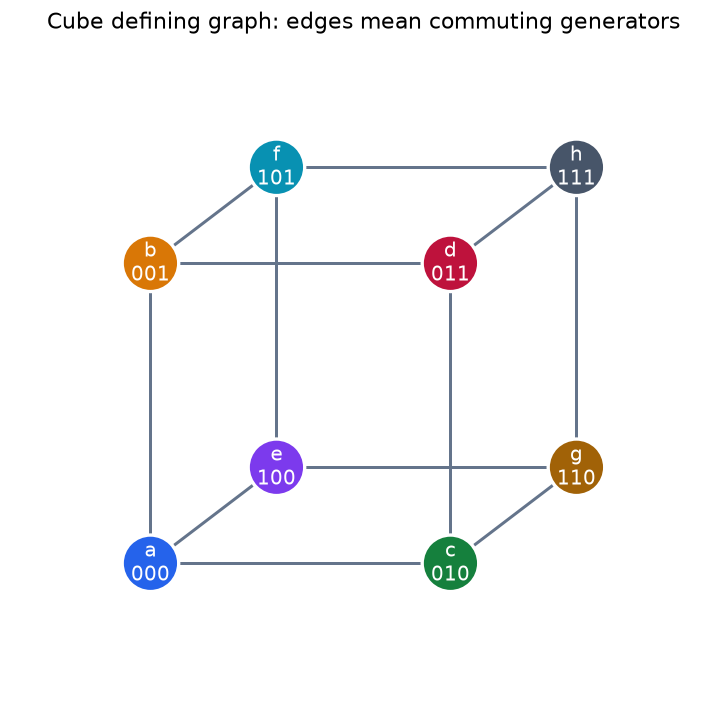

| Peripheral | Generators | Isomorphism type |
|:--|:--|:--|
| $P_{1,0}$ | $a,b,c,d$ | $D_\infty\times D_\infty$ |
| $P_{1,1}$ | $e,f,g,h$ | $D_\infty\times D_\infty$ |
| $P_{2,0}$ | $a,b,e,f$ | $D_\infty\times D_\infty$ |
| $P_{2,1}$ | $c,d,g,h$ | $D_\infty\times D_\infty$ |
| $P_{3,0}$ | $a,c,e,g$ | $D_\infty\times D_\infty$ |
| $P_{3,1}$ | $b,d,f,h$ | $D_\infty\times D_\infty$ |

In [2]:
letters = tuple('abcdefgh')
generator_bits = {s: tuple(map(int, f'{i:03b}')) for i, s in enumerate(letters)}
commutes = {s: {t for t in letters if sum(x != y for x, y in zip(generator_bits[s], generator_bits[t])) == 1}
            for s in letters}
letter_tex = {s: s for s in letters}
palette = dict(zip(letters, ['#2563eb', '#d97706', '#15803d', '#be123c',
                             '#7c3aed', '#0891b2', '#a16207', '#475569']))
defining_graph = nx.Graph()
defining_graph.add_nodes_from(letters)
defining_graph.add_edges_from((s, t) for s in letters for t in commutes[s] if s < t)
peripheral_generators = {(axis, bit): frozenset(s for s in letters if generator_bits[s][axis] == bit)
                        for axis in range(3) for bit in (0, 1)}
assert defining_graph.number_of_edges() == 12
assert all(nx.is_isomorphic(defining_graph.subgraph(face), nx.cycle_graph(4))
           for face in peripheral_generators.values())

cube_pos = {s: np.array([bits[1] + 0.42*bits[0], bits[2] + 0.32*bits[0]])
            for s, bits in generator_bits.items()}
fig_cube, ax_cube = plt.subplots(figsize=(7.5, 6))
nx.draw_networkx_edges(defining_graph, cube_pos, ax=ax_cube, width=1.8, edge_color='#64748b')
nx.draw_networkx_nodes(defining_graph, cube_pos, ax=ax_cube, node_size=1150,
                       node_color=[palette[s] for s in letters], edgecolors='white', linewidths=2)
nx.draw_networkx_labels(defining_graph, cube_pos, ax=ax_cube,
                        labels={s: s + '\n' + ''.join(map(str, generator_bits[s])) for s in letters},
                        font_color='white', font_size=12)
ax_cube.set_title('Cube defining graph: edges mean commuting generators')
ax_cube.set_aspect('equal'); ax_cube.margins(0.25); ax_cube.axis('off')
fig_cube.tight_layout()
fig_cube.savefig('coxeter_defining_cube.png', dpi=300, bbox_inches='tight')
plt.show()
rows = ['| Peripheral | Generators | Isomorphism type |', '|:--|:--|:--|']
for (axis, bit), face in peripheral_generators.items():
    rows.append(f'| $P_{{{axis+1},{bit}}}$ | $' + ','.join(sorted(face)) + r'$ | $D_\infty\times D_\infty$ |')
display(Markdown('\n'.join(rows)))

## 1. States and labeled transitions

A state records a set $F\subseteq S$ of **forbidden next letters**. Start at $F=\varnothing$. Reading an allowed letter $s\notin F$ gives
$$F\xrightarrow{s}\{s\}\cup(F\cap\operatorname{Link}(s))\cup\{t\in\operatorname{Link}(s):t<s\}.$$
Here $\operatorname{Link}(s)$ is the set of other generators commuting with $s$. The first term forbids immediate cancellation, the second carries previous obstructions through commuting letters, and the last forbids creating a lexicographically smaller representative by moving a smaller letter leftward.

Only reachable sets are retained. Breadth-first discovery in the fixed generator order assigns names $q_0,q_1,\ldots,q_{20}$. Every state is accepting; the omitted rejecting state represents invalid transitions. A table entry $q_j$ in column $s$ denotes the labeled edge $q_i\xrightarrow{s}q_j$.

This forbidden-set construction is [Jillson et al., Proposition 3.2 and Remark 3.3](https://arxiv.org/html/2406.18774v2#S3); the construction applies to arbitrary right-angled defining graphs.


In [3]:
forbidden_sets = [frozenset()]
forbidden_index = {forbidden_sets[0]: 0}
raw_transitions = []
for forbidden in forbidden_sets:
    for s in letters:
        if s in forbidden:
            continue
        following = frozenset({s} | (forbidden & commutes[s]) | {t for t in commutes[s] if t < s})
        if following not in forbidden_index:
            forbidden_index[following] = len(forbidden_sets)
            forbidden_sets.append(following)
        raw_transitions.append((forbidden_index[forbidden], s, forbidden_index[following]))

states = [f'q{i}' for i in range(len(forbidden_sets))]
idx = {state: i for i, state in enumerate(states)}
state_tex = {state: f'q_{{{i}}}' for i, state in enumerate(states)}
state_forbidden = dict(zip(states, forbidden_sets))
transitions = {state: [] for state in states}
G = nx.MultiDiGraph()
G.add_nodes_from(states)
for i, s, j in raw_transitions:
    transitions[states[i]].append((s, states[j]))
    G.add_edge(states[i], states[j], key=s, label=s)
assert len(states) == 21 and G.number_of_edges() == 109
assert all(len({s for s, _ in outgoing}) == len(outgoing) for outgoing in transitions.values())
assert G.in_degree('q0') == 0

rows = ['| State | Forbidden letters | ' + ' | '.join(letters) + ' |',
        '|:--|:--|' + ':--|'*len(letters)]
for state in states:
    following = dict(transitions[state])
    forbidden_label = ''.join(sorted(state_forbidden[state])) or '∅'
    rows.append('| ' + state + ' | ' + forbidden_label + ' | '
                + ' | '.join(following.get(s, '—') for s in letters) + ' |')
display(Markdown('\n'.join(rows)))
print(f'{len(states)} accepting states and {G.number_of_edges()} labeled transitions; no rejecting state drawn.')

| State | Forbidden letters | a | b | c | d | e | f | g | h |
|:--|:--|:--|:--|:--|:--|:--|:--|:--|:--|
| q0 | ∅ | q1 | q2 | q3 | q4 | q5 | q6 | q7 | q8 |
| q1 | a | — | q2 | q3 | q4 | q5 | q6 | q7 | q8 |
| q2 | ab | — | — | q3 | q4 | q5 | q6 | q7 | q8 |
| q3 | ac | — | q2 | — | q4 | q5 | q6 | q7 | q8 |
| q4 | bcd | q9 | — | — | — | q5 | q6 | q7 | q8 |
| q5 | ae | — | q2 | q3 | q4 | — | q6 | q7 | q8 |
| q6 | bef | q10 | — | q3 | q4 | — | — | q7 | q8 |
| q7 | ceg | q11 | q2 | — | q4 | — | q6 | — | q8 |
| q8 | dfgh | q1 | q12 | q13 | — | q14 | — | — | — |
| q9 | abc | — | — | — | q4 | q5 | q6 | q7 | q8 |
| q10 | abe | — | — | q3 | q4 | — | q6 | q7 | q8 |
| q11 | ace | — | q2 | — | q4 | — | q6 | q7 | q8 |
| q12 | abdf | — | — | q15 | — | q16 | — | q7 | q8 |
| q13 | acdg | — | q17 | — | — | q18 | q6 | — | q8 |
| q14 | aefg | — | q19 | q20 | q4 | — | — | — | q8 |
| q15 | acd | — | q17 | — | — | q5 | q6 | q7 | q8 |
| q16 | aef | — | q19 | q3 | q4 | — | — | q7 | q8 |
| q17 | abd | — | — | q15 | — | q5 | q6 | q7 | q8 |
| q18 | aeg | — | q2 | q20 | q4 | — | q6 | — | q8 |
| q19 | abf | — | — | q3 | q4 | q16 | — | q7 | q8 |
| q20 | acg | — | q2 | — | q4 | q18 | q6 | — | q8 |

21 accepting states and 109 labeled transitions; no rejecting state drawn.


## 2. The directed graph $\mathcal G$

Arrow colors identify the eight input letters, as shown in the legend. The transition table above gives every edge label explicitly; avoiding 109 overlapping text labels keeps this overview legible. The initial state sits at the center, surrounded by the other 20 states on a circle. All states are accepting. There are no self-loops: every generator is an involution, so reading it twice consecutively is forbidden.

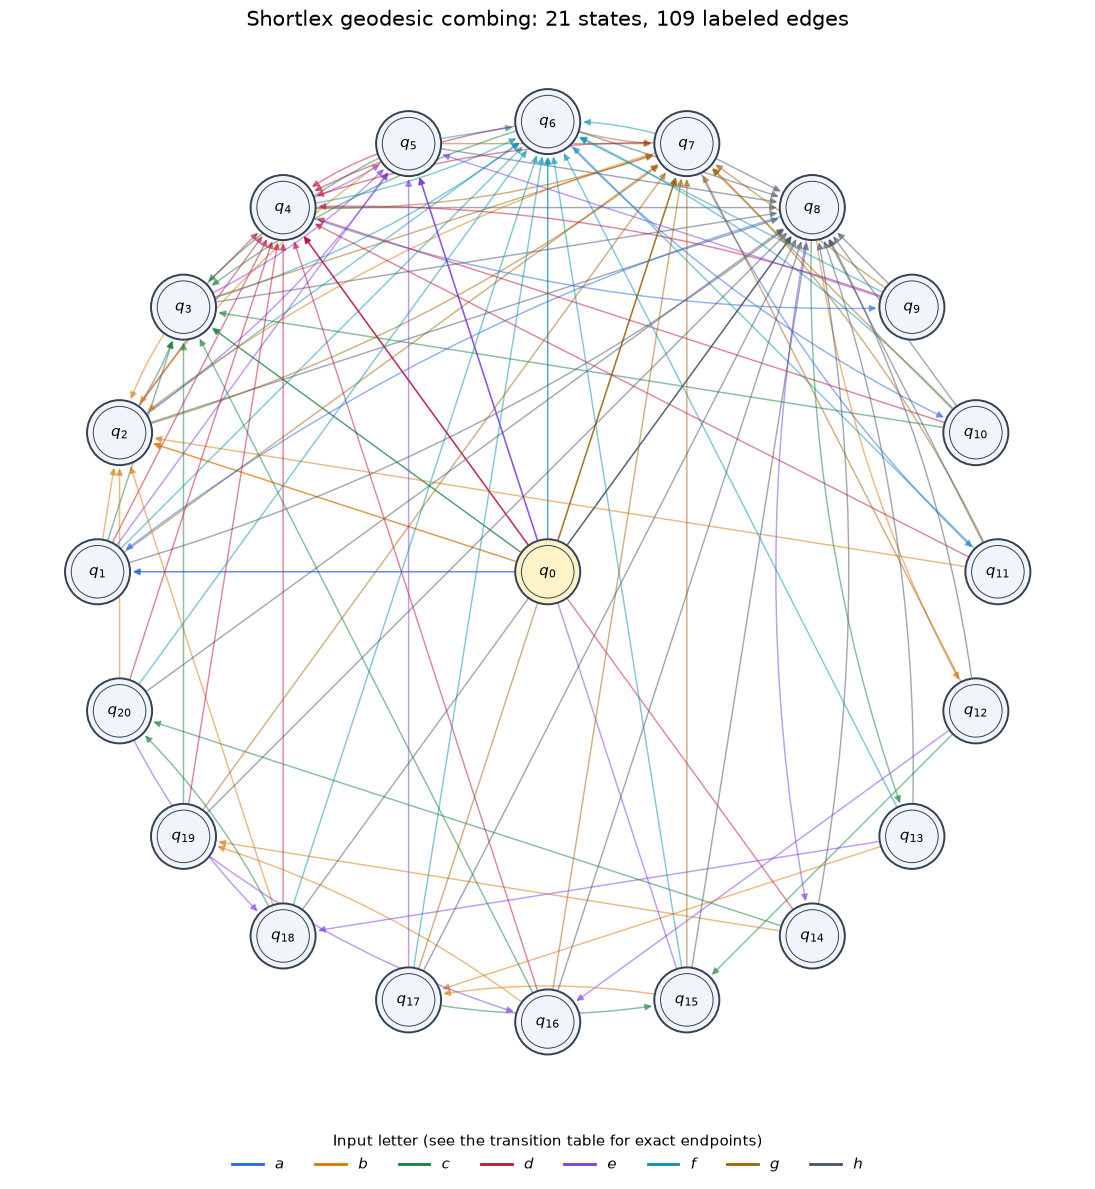

In [4]:
automaton_pos = {'q0': np.array([0.0, 0.0])}
for j, state in enumerate(states[1:]):
    angle = np.pi - 2*np.pi*j/(len(states)-1)
    automaton_pos[state] = 1.8*np.array([np.cos(angle), np.sin(angle)])
fig_automaton, ax_automaton = plt.subplots(figsize=(15, 12))
for source, target, data in G.edges(data=True):
    letter = data['label']
    rad = 0.10 if G.has_edge(target, source) else 0.0
    patch = FancyArrowPatch(automaton_pos[source], automaton_pos[target],
        connectionstyle=f'arc3,rad={rad}', arrowstyle='-|>',
        mutation_scale=10, lw=1.05, color=palette[letter],
        alpha=0.75 if source == 'q0' else 0.50,
        patchA=Circle(automaton_pos[source], 0.13, transform=ax_automaton.transData),
        patchB=Circle(automaton_pos[target], 0.13, transform=ax_automaton.transData),
        shrinkA=1, shrinkB=2, zorder=1)
    ax_automaton.add_patch(patch)
for state, point in automaton_pos.items():
    facecolor = '#fef3c7' if state == 'q0' else '#f1f5f9'
    ax_automaton.add_patch(Circle(point, 0.13, fc=facecolor, ec='#334155', lw=1.4, zorder=3))
    ax_automaton.add_patch(Circle(point, 0.105, fill=False, ec='#334155', lw=0.7, zorder=4))
    ax_automaton.text(*point, '$'+state_tex[state]+'$', ha='center', va='center', fontsize=11, zorder=5)
ax_automaton.legend(handles=[Line2D([0], [0], color=palette[s], lw=2, label='$'+s+'$') for s in letters],
                     loc='upper center', bbox_to_anchor=(0.5, -0.01), ncol=8, frameon=False,
                     title='Input letter (see the transition table for exact endpoints)')
ax_automaton.set_title('Shortlex geodesic combing: 21 states, 109 labeled edges', fontsize=15)
ax_automaton.set_aspect('equal'); ax_automaton.set_xlim(-2.15, 2.15); ax_automaton.set_ylim(-2.15, 2.15)
ax_automaton.axis('off'); fig_automaton.tight_layout()
fig_automaton.savefig('coxeter_automaton.png', dpi=300, bbox_inches='tight')
plt.show()

## 3. Adjacency matrix and growth

Use the state order $(q_0,\ldots,q_{20})$. The entry $M_{ij}$ counts labeled edges from $q_i$ to $q_j$. We build a multigraph so that distinct labels would be counted separately; for this automaton every entry happens to be $0$ or $1$. The initial column is zero.

The sphere-growth series is
$$\sum_{n\ge0}|S_n(W,S)|t^n=\frac{(1+t)^2}{(1-t)(1-5t)}.$$
In particular, $|S_0|=1$ and $|S_n|=9\cdot5^{n-1}-1$ for $n\ge1$. Thus the exponential growth rate is $\lambda=5$.

In [5]:
M = nx.to_numpy_array(G, nodelist=states, dtype=int, weight=None)
M_exact = sp.Matrix(M)
assert M_exact[:, 0] == sp.zeros(len(states), 1)
assert max(M_exact) == 1
pf_spectrum = M_exact.eigenvals()
assert pf_spectrum == {sp.Integer(5): 1, sp.Integer(1): 4, sp.Integer(-1): 9, sp.Integer(0): 7}
display(Math(r'\text{State order: }('+','.join(state_tex[s] for s in states)+')'))
display(Math(r'M='+sp.latex(M_exact)))
x = sp.symbols('x')
display(Math(r'\chi_M(x)='+sp.latex(sp.factor(M_exact.charpoly(x).as_expr()))))
display(Math(r'\operatorname{spec}(M)=\{5^{(1)},1^{(4)},(-1)^{(9)},0^{(7)}\}'))
t = sp.symbols('t')
transfer_growth = sp.factor((sp.eye(len(states))-t*M_exact).inv()[0, :].dot(sp.ones(len(states), 1)))
assert sp.cancel(transfer_growth-(1+t)**2/((1-t)*(1-5*t))) == 0
display(Math(r'\mathbf e_0^T(I-tM)^{-1}\mathbf1='+sp.latex(transfer_growth)))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### Exact Perron–Frobenius data and the vertex measure

Use the manuscript's normalization, exactly as in the $\mathbb Z*\mathbb Z^2$ notebook:
$$r=\lim_{n\to\infty}\frac1n\sum_{k=0}^{n}\lambda^{-k}M^k\mathbf1,
\qquad \ell=\lim_{n\to\infty}\frac1n\sum_{k=0}^{n}\lambda^{-k}(M^T)^k\mathbf e_0.$$
Since $5$ is simple and strictly dominant, its spectral projection is $P=u v^T/(v^Tu)$, giving $r=P\mathbf1$ and $\ell=P^T\mathbf e_0$. These are not independently normalized eigenvectors.

Define $N_{ij}=M_{ij}r_j/(\lambda r_i)$ when $r_i>0$, and use an identity row if $r_i=0$. The stationary vertex measure is $\mu_i=r_i\ell_i/\sum_jr_j\ell_j$. It is distinct from the based path law starting at $q_0$. All entries in this example are rational. The full exact matrices are retained in `M_exact`, `N`, and later `M_C`, `N_C`.

In [6]:
num_states = len(states)
I = sp.eye(num_states)
ones = sp.ones(num_states, 1)
e0 = I[:, idx['q0']]
lam = sp.Integer(5)
assert pf_spectrum[lam] == 1 and all(abs(value) < lam for value in pf_spectrum if value != lam)
u = (M_exact-lam*I).nullspace()[0]
v = (M_exact.T-lam*I).nullspace()[0]
P = (u*v.T/v.dot(u)).applyfunc(sp.simplify)
r = (P*ones).applyfunc(sp.simplify)
l = (P.T*e0).applyfunc(sp.simplify)
N = sp.Matrix(num_states, num_states,
    lambda i, j: sp.simplify(M_exact[i,j]*r[j]/(lam*r[i])) if r[i] != 0 else sp.Integer(i == j))
mu_weights = r.multiply_elementwise(l)
mu = (mu_weights/sum(mu_weights)).applyfunc(sp.simplify)
assert P*P == P
assert M_exact*r == lam*r and M_exact.T*l == lam*l
assert N*ones == ones and N.T*mu == mu and sum(mu) == 1
assert all(value >= 0 for value in r) and all(value >= 0 for value in l)
assert all(value >= 0 for value in N) and all(value >= 0 for value in mu)
assert mu[idx['q0']] == 0

display(Math(r'\lambda='+sp.latex(lam)))
rows = [r'| State | $r_i$ | $\ell_i$ | $\mu_i$ |', '|:--|--:|--:|--:|']
for state in states:
    i = idx[state]
    rows.append('| $'+state_tex[state]+'$ | $'+sp.latex(r[i])+'$ | $'+sp.latex(l[i])+'$ | $'+sp.latex(mu[i])+'$ |')
display(Markdown('\n'.join(rows)))
display(Math(r'N='+sp.latex(N)))
print('Exact checks passed: projection, PF equations, nonnegativity, stochasticity, and stationarity.')

<IPython.core.display.Math object>

| State | $r_i$ | $\ell_i$ | $\mu_i$ |
|:--|--:|--:|--:|
| $q_{0}$ | $\frac{9}{5}$ | $0$ | $0$ |
| $q_{1}$ | $\frac{3}{2}$ | $\frac{3}{50}$ | $\frac{1}{20}$ |
| $q_{2}$ | $\frac{5}{4}$ | $\frac{3}{25}$ | $\frac{1}{12}$ |
| $q_{3}$ | $\frac{5}{4}$ | $\frac{3}{25}$ | $\frac{1}{12}$ |
| $q_{4}$ | $1$ | $\frac{9}{40}$ | $\frac{1}{8}$ |
| $q_{5}$ | $\frac{5}{4}$ | $\frac{3}{25}$ | $\frac{1}{12}$ |
| $q_{6}$ | $1$ | $\frac{9}{40}$ | $\frac{1}{8}$ |
| $q_{7}$ | $1$ | $\frac{9}{40}$ | $\frac{1}{8}$ |
| $q_{8}$ | $\frac{3}{4}$ | $\frac{3}{10}$ | $\frac{1}{8}$ |
| $q_{9}$ | $1$ | $\frac{9}{200}$ | $\frac{1}{40}$ |
| $q_{10}$ | $1$ | $\frac{9}{200}$ | $\frac{1}{40}$ |
| $q_{11}$ | $1$ | $\frac{9}{200}$ | $\frac{1}{40}$ |
| $q_{12}$ | $\frac{3}{4}$ | $\frac{3}{50}$ | $\frac{1}{40}$ |
| $q_{13}$ | $\frac{3}{4}$ | $\frac{3}{50}$ | $\frac{1}{40}$ |
| $q_{14}$ | $\frac{3}{4}$ | $\frac{3}{50}$ | $\frac{1}{40}$ |
| $q_{15}$ | $1$ | $\frac{3}{200}$ | $\frac{1}{120}$ |
| $q_{16}$ | $1$ | $\frac{3}{200}$ | $\frac{1}{120}$ |
| $q_{17}$ | $1$ | $\frac{3}{200}$ | $\frac{1}{120}$ |
| $q_{18}$ | $1$ | $\frac{3}{200}$ | $\frac{1}{120}$ |
| $q_{19}$ | $1$ | $\frac{3}{200}$ | $\frac{1}{120}$ |
| $q_{20}$ | $1$ | $\frac{3}{200}$ | $\frac{1}{120}$ |

<IPython.core.display.Math object>

Exact checks passed: projection, PF equations, nonnegativity, stochasticity, and stationarity.


## 4. Component quotient and maximal component

There are exactly two strongly connected components: $C_0=\{q_0\}$ and $C_1=\{q_1,\ldots,q_{20}\}$. The component quotient has one arrow $C_0\to C_1$; internal edges are suppressed. The noninitial component is terminal and maximal, with spectral radius $5$.

Although the **Cayley graph is bipartite**, this finite automaton forgets word parity. Its maximal component is **aperiodic**: there are cycles of lengths two and three. Consequently the Markov chain on this component is mixing; sampling every $k$ steps does not introduce periodic classes.

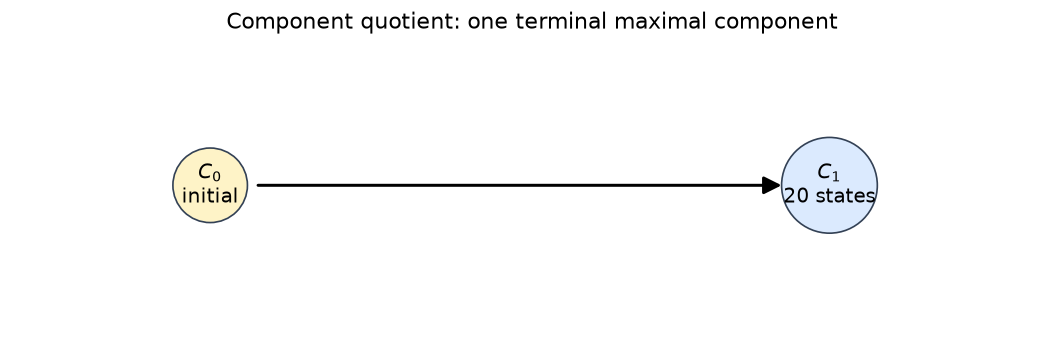

In [7]:
components = sorted(nx.strongly_connected_components(G), key=lambda comp: min(idx[s] for s in comp))
assert components == [{'q0'}, set(states[1:])]
component_of = {s: i for i, comp in enumerate(components) for s in comp}
quotient = nx.DiGraph()
quotient.add_nodes_from(range(len(components)))
for u, v in G.edges():
    if component_of[u] != component_of[v]: quotient.add_edge(component_of[u], component_of[v])
assert set(quotient.edges()) == {(0, 1)}
component_C = components[1]
assert nx.is_aperiodic(nx.DiGraph(G.subgraph(component_C)))
# q11 -> q7 -> q11 reads ga; q11 -> q2 -> q7 -> q11 reads bga.
for cycle in [('q11','q7','q11'), ('q11','q2','q7','q11')]:
    assert all(G.has_edge(u,v) for u,v in zip(cycle,cycle[1:]))

fig_quotient, ax_quotient = plt.subplots(figsize=(9, 3))
quotient_pos = {0: (0,0), 1: (2.5,0)}
nx.draw_networkx_nodes(quotient, quotient_pos, ax=ax_quotient, node_size=[2000,3300],
                       node_color=['#fef3c7','#dbeafe'], edgecolors='#334155')
nx.draw_networkx_edges(quotient, quotient_pos, ax=ax_quotient, arrows=True, arrowstyle='-|>',
                       arrowsize=22, node_size=3300, width=1.8)
nx.draw_networkx_labels(quotient, quotient_pos, ax=ax_quotient,
                        labels={0:'$C_0$\ninitial',1:'$C_1$\n20 states'}, font_size=12)
ax_quotient.set_xlim(-0.8,3.4); ax_quotient.set_ylim(-0.55,0.55); ax_quotient.axis('off')
ax_quotient.set_title('Component quotient: one terminal maximal component')
fig_quotient.tight_layout()
fig_quotient.savefig('coxeter_component_quotient.png', dpi=300, bbox_inches='tight')
plt.show()

### Exact data on $C=C_1$

Let $M_C$ be the $20\times20$ principal submatrix in inherited state order. Compute $\lambda_C$, its spectral projection $P_C$, and $r_C=P_C\mathbf1_C$ using the same normalization. Then
$$(N_C)_{ij}=\frac{(M_C)_{ij}(r_C)_j}{\lambda_C(r_C)_i}.$$
Because $C$ is terminal, $r_C$ is the restriction of $r$, and $N_C$ is the restriction of $N$.

In [8]:
states_C = [state for state in states if state in component_C]
indices_C = [idx[s] for s in states_C]
M_C = M_exact.extract(indices_C, indices_C)
spectrum_C = M_C.eigenvals()
lam_C = max(spectrum_C)
assert lam_C == lam and spectrum_C[lam_C] == 1
size_C = len(states_C)
u_C = (M_C-lam_C*sp.eye(size_C)).nullspace()[0]
v_C = (M_C.T-lam_C*sp.eye(size_C)).nullspace()[0]
P_C = (u_C*v_C.T/v_C.dot(u_C)).applyfunc(sp.simplify)
r_C = (P_C*sp.ones(size_C,1)).applyfunc(sp.simplify)
N_C = sp.Matrix(size_C,size_C, lambda i,j: sp.simplify(M_C[i,j]*r_C[j]/(lam_C*r_C[i])))
mu_C = mu.extract(indices_C,[0])
assert M_C*r_C == lam_C*r_C
assert r_C == r.extract(indices_C,[0])
assert N_C == N.extract(indices_C,indices_C)
assert N_C*sp.ones(size_C,1) == sp.ones(size_C,1)
assert N_C.T*mu_C == mu_C and sum(mu_C) == 1
assert all(value > 0 for value in r_C)
display(Math(r'\lambda_C='+sp.latex(lam_C)))
display(Math(r'M_C='+sp.latex(M_C)))
display(Math(r'N_C='+sp.latex(N_C)))
print('Exact component checks passed; C is terminal, irreducible, and aperiodic.')

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Exact component checks passed; C is terminal, irreducible, and aperiodic.


## 5. Why this is a geodesic combing

In a right-angled Coxeter group, a word is reduced exactly when it contains no two occurrences of the same generator separated entirely by letters commuting with that generator. Any two reduced expressions for the same element differ by adjacent commutations. Among reduced words, the lexicographically least representative is characterized by the absence of a subword $tus$ with $s<t$ and every letter of $tu$ commuting with $s$: otherwise $s$ can move to the left of $t$ and lower the word.

These are exactly the two types of forbidden next letters propagated by the state update. The automaton therefore accepts one reduced word for each group element. Its accepted language is prefix-closed, since a shorter or lexicographically smaller representative for a prefix would improve the whole word. Thus it is a bijective geodesic combing.

For an independent finite check, the next cell reduces words by commuting-and-canceling equal letters, then computes the lexicographically least topological ordering of the remaining dependence graph. This normalizer does **not** use the automaton. Breadth-first search in the group is compared with accepted paths and the exact growth formula. The check uses `check_depth = 5`; it does not enumerate long random paths.

In [9]:
@lru_cache(maxsize=200000)
def _canonical_tuple(word):
    # Cancel equal letters when every intervening letter commutes with them.
    reduced = []
    for s in word:
        for j in range(len(reduced)-1, -1, -1):
            t = reduced[j]
            if t == s:
                reduced.pop(j)
                break
            if t not in commutes[s]:
                reduced.append(s)
                break
        else:
            reduced.append(s)
    # Noncommuting occurrences retain their order. A greedy topological sort
    # chooses the lexicographically least representative of this reduced trace.
    successors = [[] for _ in reduced]
    indegree = [0]*len(reduced)
    for i, s in enumerate(reduced):
        for j in range(i+1,len(reduced)):
            if reduced[j] not in commutes[s]:
                successors[i].append(j)
                indegree[j] += 1
    ready = [(reduced[i],i) for i,d in enumerate(indegree) if d == 0]
    heapq.heapify(ready)
    normal = []
    while ready:
        s,i = heapq.heappop(ready)
        normal.append(s)
        for j in successors[i]:
            indegree[j] -= 1
            if indegree[j] == 0: heapq.heappush(ready,(reduced[j],j))
    assert len(normal) == len(reduced)
    return tuple(normal)

def canonical_word(word):
    word = tuple(word)
    if any(s not in commutes for s in word):
        raise ValueError('Use only generators a,b,c,d,e,f,g,h.')
    return _canonical_tuple(word)

def cayley_multiply(g, s):
    return canonical_word(tuple(g)+(s,))

def word_path(word):
    state, path = 'q0', ['q0']
    for s in word:
        following = dict(transitions[state])
        if s not in following: raise ValueError(f'Not a shortlex combing word: {state} --{s}--> ?')
        state = following[s]
        path.append(state)
    return path

check_depth = 5
assert isinstance(check_depth, int) and 0 <= check_depth <= 6, 'Use a check_depth between 0 and 6.'
check_distances = {():0}
frontier = [()]
for depth in range(check_depth):
    following_frontier = []
    for g in frontier:
        for s in letters:
            h = cayley_multiply(g,s)
            assert cayley_multiply(h,s) == g
            if h not in check_distances:
                check_distances[h] = depth+1
                following_frontier.append(h)
    frontier = following_frontier

accepted = {(): 'q0'}
level_words = {(): 'q0'}
for depth in range(check_depth):
    next_words = {}
    for word, state in level_words.items():
        for s, following in transitions[state]:
            new_word = word+(s,)
            assert canonical_word(new_word) == new_word
            next_words[new_word] = following
    accepted.update(next_words)
    level_words = next_words
assert set(accepted) == set(check_distances)
assert all(len(word) == distance for word,distance in check_distances.items())
# Exhaust all input words to depth four, including nongeodesic representatives.
for length in range(min(check_depth,4)+1):
    for word in itertools.product(letters,repeat=length):
        normal = canonical_word(word)
        assert len(normal) <= len(word)
        assert normal in accepted
        assert word_path(normal)[-1] == accepted[normal]
        assert canonical_word(normal) == normal
sphere_counts = [sum(d == n for d in check_distances.values()) for n in range(check_depth+1)]
expected_counts = [1]+[9*5**(n-1)-1 for n in range(1,check_depth+1)]
assert sphere_counts == expected_counts
print('Sphere counts:',sphere_counts)
print(f'Checked {len(check_distances):,} group elements through radius {check_depth}: '
      'unique accepted representatives, geodesy, involutions, and growth counts.')

Sphere counts: [1, 8, 44, 224, 1124, 5624]
Checked 7,025 group elements through radius 5: unique accepted representatives, geodesy, involutions, and growth counts.


### Independent matrix-representation check

The faithful geometric (Tits) representation gives an additional check independent of both the forbidden-set automaton and the word normalizer. In the basis indexed by $S$, the Gram matrix has diagonal $1$, commuting entries $0$, and other off-diagonal entries $-1$. The reflection $s_i$ changes only row $i$ of the identity: its diagonal entry becomes $-1$, and entries corresponding to noncommuting generators become $2$.

We compare breadth-first search using these integer matrices with the accepted paths. This checks that each element in the finite ball has exactly one accepted representative, of minimum length. The all-length conclusion follows from the preceding normal-form argument, not from this finite check alone.


In [10]:
# The row-sum bound 9^depth keeps this bounded calculation exact in int64.
assert 9**check_depth < np.iinfo(np.int64).max, 'Reduce check_depth to avoid integer overflow.'
tits_identity = np.eye(len(letters), dtype=np.int64)
tits_reflections = {}
for i, s in enumerate(letters):
    reflection = tits_identity.copy()
    reflection[i,i] = -1
    for j, t in enumerate(letters):
        if t != s and t not in commutes[s]: reflection[i,j] = 2
    assert np.array_equal(reflection @ reflection, tits_identity)
    tits_reflections[s] = reflection
for s in letters:
    for t in commutes[s]:
        assert np.array_equal(tits_reflections[s] @ tits_reflections[t],
                              tits_reflections[t] @ tits_reflections[s])

tits_distance = {tits_identity.tobytes(): 0}
tits_frontier = [tits_identity]
for depth in range(1,check_depth+1):
    following_frontier = []
    for matrix in tits_frontier:
        for reflection in tits_reflections.values():
            following = matrix @ reflection
            key = following.tobytes()
            if key not in tits_distance:
                tits_distance[key] = depth
                following_frontier.append(following)
    tits_frontier = following_frontier

tits_accepted = {tits_identity.tobytes(): ()}
tits_paths = [((), 'q0', tits_identity)]
for depth in range(1,check_depth+1):
    following_paths = []
    for word, state, matrix in tits_paths:
        for s, following_state in transitions[state]:
            following = matrix @ tits_reflections[s]
            key = following.tobytes()
            assert key not in tits_accepted, 'Two accepted words represent the same element.'
            assert tits_distance[key] == depth, 'An accepted representative is not geodesic.'
            tits_accepted[key] = word+(s,)
            following_paths.append((word+(s,),following_state,following))
    tits_paths = following_paths
assert tits_accepted.keys() == tits_distance.keys()
assert set(tits_accepted.values()) == set(check_distances)
print(f'Independent Tits-matrix check passed through radius {check_depth}: '
      f'{len(tits_distance):,} elements, one shortest accepted representative each.')


Independent Tits-matrix check passed through radius 5: 7,025 elements, one shortest accepted representative each.


## 6. A finite Cayley graph with the combing highlighted

The induced word-metric ball for $S=\{a,b,c,d,e,f,g,h\}$ contains **every** generator edge whose two endpoints are in the ball. Each generator is its own inverse, so Cayley edges are undirected. The colored arrows select the shortlex combing tree and point away from the identity $1$.

The default `cayley_radius = 2` gives 53 group vertices. Increase it to 3 for 277 vertices. The main picture is a deterministic two-dimensional layout of this finite graph: crossings do not create vertices and drawn lengths are not word distances. The separate inset gives actual lattice coordinates in the identity peripheral subgroup $P_{1,0}=\langle a,b,c,d\rangle\cong D_\infty\times D_\infty$.

Unlike the free-product example, the six peripheral families **overlap**. Every group vertex belongs to one left coset of each of the six subgroups. We therefore do not draw the whole graph as a disjoint collection of grids. Run Sections 1 and 5 before this section.

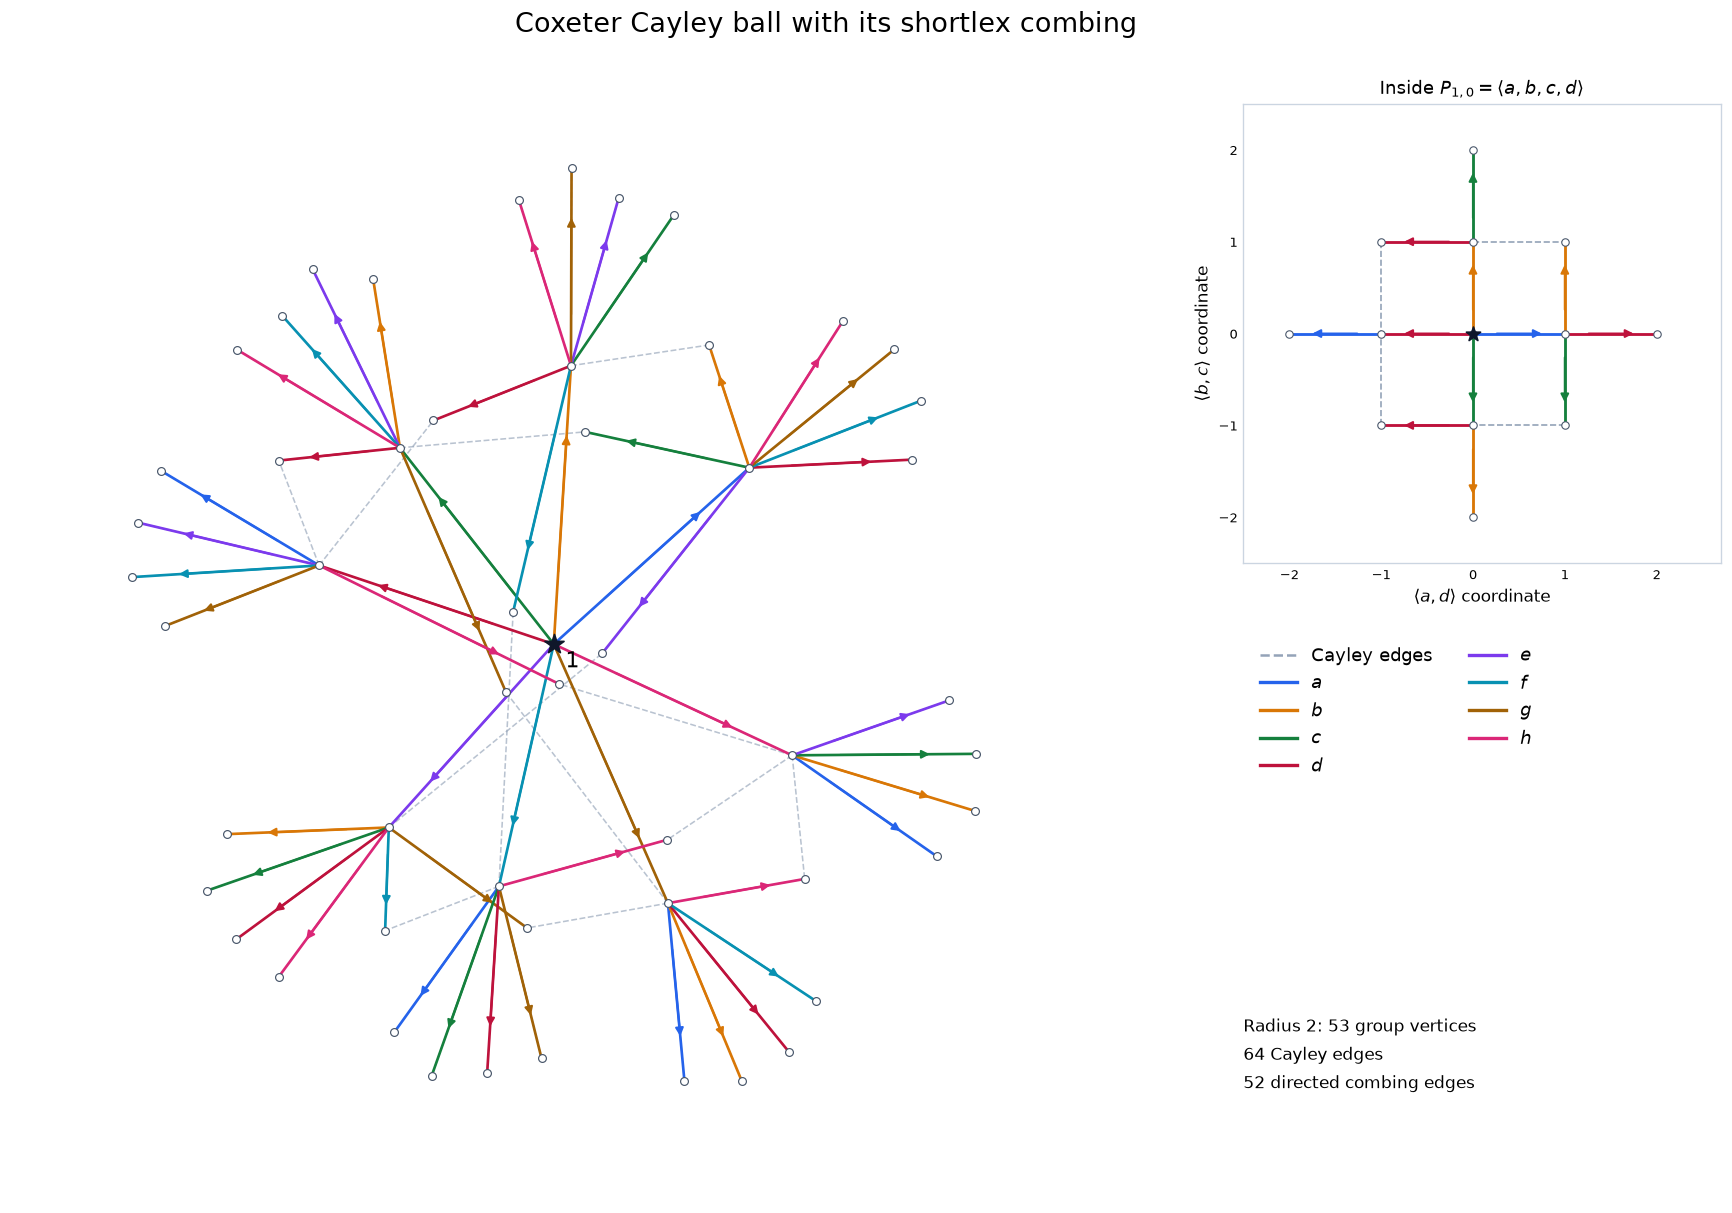

53 vertices; 64 Cayley edges; 52 combing edges; 150 intersected peripheral cosets.


In [11]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from matplotlib.patches import FancyArrowPatch

cayley_radius = 2
if not isinstance(cayley_radius, int) or cayley_radius < 1:
    raise ValueError('cayley_radius must be a positive integer.')

cayley_distance = {(): 0}
frontier = [()]
for depth in range(cayley_radius):
    next_frontier = []
    for g in frontier:
        for s in letters:
            h = cayley_multiply(g, s)
            if h not in cayley_distance:
                cayley_distance[h] = depth + 1
                next_frontier.append(h)
    frontier = next_frontier
cayley_ball = nx.Graph()
cayley_ball.add_nodes_from(cayley_distance)
for g in cayley_distance:
    for s in letters:
        h = cayley_multiply(g, s)
        if h in cayley_distance:
            cayley_ball.add_edge(g, h, generator=s)

combing_tree = nx.Graph()
combing_tree.add_nodes_from(cayley_ball)
for g in cayley_ball:
    assert len(g) == cayley_distance[g]
    if g:
        assert g[:-1] in cayley_ball and cayley_ball.has_edge(g[:-1], g)
        combing_tree.add_edge(g[:-1], g)
assert nx.is_tree(combing_tree)
assert all(abs(cayley_distance[g] - cayley_distance[h]) == 1 for g, h in cayley_ball.edges())

# Begin with evenly spaced first-letter branches, then relax the finite graph.
children = {g: sorted(h for h in combing_tree[g] if len(h) > len(g)) for g in combing_tree}
weights = {}
for g in sorted(cayley_ball, key=len, reverse=True):
    weights[g] = max(1, sum(weights[h] for h in children[g]))
sectors = {(): (0.0, 2*np.pi)}
initial_positions = {(): np.zeros(2)}
for g in sorted(cayley_ball, key=lambda g: (len(g), g)):
    low, high = sectors[g]
    total = sum(weights[h] for h in children[g])
    cursor = low
    for h in children[g]:
        width = (high-low) * weights[h] / total
        sectors[h] = (cursor, cursor+width)
        angle = cursor + width/2
        initial_positions[h] = len(h) * np.array([np.cos(angle), np.sin(angle)])
        cursor += width
cayley_pos = nx.spring_layout(cayley_ball, pos=initial_positions, fixed=[()],
                              seed=67, k=0.72, iterations=100)
edge_lengths = [np.linalg.norm(cayley_pos[g]-cayley_pos[h]) for g,h in cayley_ball.edges()]
plot_spacing = float(np.median(edge_lengths))
letter_colors = dict(zip(letters, ['#2563eb','#d97706','#15803d','#be123c',
                                   '#7c3aed','#0891b2','#a16207','#db2777']))
cayley_gray = '#94a3b8'
cone_red = '#dc2626'

# Standard parabolic cosets gP are identified by their unique shortest representative.
# A right descent can be moved to the end by commuting past all later letters.
def parabolic_representative(g, subgroup_generators):
    representative = tuple(g)
    while True:
        for i in range(len(representative)-1, -1, -1):
            s = representative[i]
            if s in subgroup_generators and all(t in commutes[s] for t in representative[i+1:]):
                representative = canonical_word(representative[:i] + representative[i+1:])
                break
        else:
            return representative

peripheral_cosets = {}
vertex_peripheral_cosets = {}
for g in cayley_ball:
    vertex_peripheral_cosets[g] = []
    for family, generators in sorted(peripheral_generators.items()):
        key = (family, parabolic_representative(g, generators))
        peripheral_cosets.setdefault(key, []).append(g)
        vertex_peripheral_cosets[g].append(key)
assert all(len(keys) == 6 for keys in vertex_peripheral_cosets.values())
# Multiplication by a peripheral generator stays in the same coset, whenever visible.
for family, generators in peripheral_generators.items():
    for g, h, data in cayley_ball.edges(data=True):
        if data['generator'] in generators:
            assert parabolic_representative(g, generators) == parabolic_representative(h, generators)

# The inset uses a true square lattice for one identity peripheral coset.
detail_family = (0, 0)
detail_generators = peripheral_generators[detail_family]
detail_vertices = peripheral_cosets[(detail_family, ())]
first = min(detail_generators)
opposite = next(s for s in sorted(detail_generators) if s != first and s not in commutes[first])
detail_pairs = [(first, opposite), tuple(sorted(detail_generators - {first, opposite}))]
def dihedral_line_coordinate(word, pair):
    subword = tuple(s for s in word if s in pair)
    assert all(x != y for x,y in zip(subword, subword[1:]))
    return 0 if not subword else len(subword) * (1 if subword[0] == pair[0] else -1)
detail_pos = {g: np.array([dihedral_line_coordinate(g,pair) for pair in detail_pairs], dtype=float)
              for g in detail_vertices}
assert len({tuple(p) for p in detail_pos.values()}) == len(detail_vertices)
for g, h in cayley_ball.subgraph(detail_vertices).edges():
    assert np.abs(detail_pos[g]-detail_pos[h]).sum() == 1

def draw_cayley_arrow(axis, g, h, positions, color, size=11):
    if cayley_distance[g] > cayley_distance[h]:
        g, h = h, g
    start, end = np.asarray(positions[g]), np.asarray(positions[h])
    direction = end-start
    axis.add_patch(FancyArrowPatch(start+0.26*direction, start+0.75*direction,
                    arrowstyle='-|>', mutation_scale=size, color=color, lw=1.25,
                    shrinkA=0, shrinkB=0, zorder=5))

def draw_coxeter_cayley(mode='plain', highlight_word=()):
    if mode not in {'plain','combing','coned','path'}:
        raise ValueError('Unknown plot mode.')
    path_vertices = [()]
    if mode == 'path':
        for s in highlight_word:
            path_vertices.append(cayley_multiply(path_vertices[-1],s))
        if any(g not in cayley_ball for g in path_vertices):
            raise ValueError('Increase cayley_radius and rerun Section 6 to include this path.')
        assert all(cayley_ball.has_edge(g,h) for g,h in zip(path_vertices,path_vertices[1:]))
    fig = plt.figure(figsize=(15,10), constrained_layout=True)
    grid = fig.add_gridspec(2,2, width_ratios=[3.0,1.15], height_ratios=[1,1])
    ax = fig.add_subplot(grid[:,0])
    detail = fig.add_subplot(grid[0,1])
    note = fig.add_subplot(grid[1,1]); note.axis('off')
    all_segments = [(cayley_pos[g],cayley_pos[h]) for g,h in cayley_ball.edges()]
    ax.add_collection(LineCollection(all_segments, colors=cayley_gray, linestyles='dashed',
                                     linewidths=0.95, alpha=0.65, zorder=1))
    if mode == 'combing':
        for g,h in combing_tree.edges():
            s = cayley_ball[g][h]['generator']
            points = np.array([cayley_pos[g],cayley_pos[h]])
            ax.plot(points[:,0], points[:,1], color=letter_colors[s], lw=1.6, zorder=3)
            draw_cayley_arrow(ax,g,h,cayley_pos,letter_colors[s],size=10)
    if mode == 'coned':
        segments = [(cone_positions[key],cayley_pos[g])
                    for key,members in peripheral_cosets.items() for g in members]
        ax.add_collection(LineCollection(segments, colors=cone_red, linewidths=0.65,
                                         alpha=0.45, zorder=2))
        cone_xy = np.array(list(cone_positions.values()))
        ax.scatter(cone_xy[:,0],cone_xy[:,1],s=12,marker='D',color=cone_red,
                    edgecolors='white',linewidths=0.25,zorder=4)
    points = np.array(list(cayley_pos.values()))
    ax.scatter(points[:,0],points[:,1],s=22,facecolors='white',edgecolors='#475569',lw=0.7,zorder=6)
    ax.scatter([0],[0],s=145,marker='*',color='#0f172a',zorder=8)
    ax.annotate('$1$',(0,0),xytext=(7,-14),textcoords='offset points',fontsize=13,zorder=9)
    if mode == 'path':
        for s,g,h in zip(highlight_word,path_vertices,path_vertices[1:]):
            points = np.array([cayley_pos[g],cayley_pos[h]])
            ax.plot(points[:,0],points[:,1],color=letter_colors[s],lw=3.0,zorder=7)
            # Follow the word's actual direction, even for a nongeodesic custom word.
            start,end=points; delta=end-start
            ax.add_patch(FancyArrowPatch(start+0.25*delta,start+0.75*delta,
                arrowstyle='-|>',mutation_scale=16,lw=2,color=letter_colors[s],zorder=8))
        for g in dict.fromkeys(path_vertices[1:]):
            ax.annotate('$'+''.join(g)+'$',cayley_pos[g],xytext=(7,7),
                textcoords='offset points',fontsize=12,zorder=10,
                bbox=dict(fc='white',ec='none',alpha=0.9,pad=1))
    group_points = np.array(list(cayley_pos.values()))
    margin = 0.65*plot_spacing
    ax.set(xlim=(group_points[:,0].min()-margin,group_points[:,0].max()+margin),
           ylim=(group_points[:,1].min()-margin,group_points[:,1].max()+margin),aspect='equal')
    ax.axis('off')

    # Identical identity-peripheral lattice insets across the figures.
    for g,h,data in cayley_ball.subgraph(detail_vertices).edges(data=True):
        points = np.array([detail_pos[g],detail_pos[h]])
        colored = mode == 'combing' and combing_tree.has_edge(g,h)
        detail.plot(points[:,0],points[:,1],color=letter_colors[data['generator']] if colored else cayley_gray,
                    lw=1.7 if colored else 1.0,ls='-' if colored else '--',zorder=1)
        if colored:
            draw_cayley_arrow(detail,g,h,detail_pos,letter_colors[data['generator']],size=10)
    if mode == 'coned':
        local_cone = np.array([0.42,cayley_radius+0.65])
        for g in detail_vertices:
            detail.plot([local_cone[0],detail_pos[g][0]],[local_cone[1],detail_pos[g][1]],
                         color=cone_red,lw=0.9,alpha=0.65,zorder=2)
        detail.scatter(*local_cone,color=cone_red,marker='D',s=45,zorder=6)
        detail.annotate('$v_{P_{1,0}}$',local_cone,xytext=(8,4),textcoords='offset points',
                        fontsize=11,color=cone_red)
    if mode == 'path':
        for s,g,h in zip(highlight_word,path_vertices,path_vertices[1:]):
            if g in detail_pos and h in detail_pos:
                points = np.array([detail_pos[g],detail_pos[h]])
                detail.plot(points[:,0],points[:,1],color=letter_colors[s],lw=2.7,zorder=3)
                start,end=points; delta=end-start
                detail.add_patch(FancyArrowPatch(start+0.20*delta,start+0.75*delta,
                    arrowstyle='-|>',mutation_scale=12,lw=1.8,color=letter_colors[s],zorder=5))
    points=np.array(list(detail_pos.values()))
    detail.scatter(points[:,0],points[:,1],s=20,facecolors='white',edgecolors='#475569',lw=0.65,zorder=4)
    detail.scatter([0],[0],s=80,marker='*',color='#0f172a',zorder=6)
    detail.set(xlim=(-cayley_radius-0.5,cayley_radius+0.7),
               ylim=(-cayley_radius-0.5,cayley_radius+(1.2 if mode=='coned' else 0.5)),aspect='equal')
    detail.set_xticks(range(-cayley_radius,cayley_radius+1)); detail.set_yticks(range(-cayley_radius,cayley_radius+1))
    detail.tick_params(labelsize=8,length=0)
    detail.set_title(r'Inside $P_{1,0}=\langle a,b,c,d\rangle$',fontsize=11)
    detail.set_xlabel(r'$\langle a,d\rangle$ coordinate',fontsize=10)
    detail.set_ylabel(r'$\langle b,c\rangle$ coordinate',fontsize=10)
    for spine in detail.spines.values(): spine.set_color('#cbd5e1')
    handles=[Line2D([0],[0],color=cayley_gray,ls='--',label='Cayley edges')]
    if mode in {'combing','path'}:
        chosen=letters if mode=='combing' else tuple(dict.fromkeys(highlight_word))
        handles += [Line2D([0],[0],color=letter_colors[s],lw=2,label='$'+s+'$') for s in chosen]
    if mode=='coned':
        handles += [Line2D([0],[0],color=cone_red,lw=1,label='Cone edges'),
                    Line2D([0],[0],marker='D',color='none',markerfacecolor=cone_red,label='Cone vertices')]
    note.legend(handles=handles,loc='upper left',frameon=False,ncol=2 if mode=='combing' else 1)
    information=f'Radius {cayley_radius}: {len(cayley_ball)} group vertices\n{cayley_ball.number_of_edges()} Cayley edges'
    if mode=='combing': information+=f'\n{combing_tree.number_of_edges()} directed combing edges'
    if mode=='coned': information+=f'\n{len(peripheral_cosets)} cone vertices\n{6*len(cayley_ball)} cone edges\n\nAll six peripheral families are included.\nThe inset isolates one identity coset.'
    if mode=='path': information+='\nPath: '+('1 → '+' → '.join(''.join(highlight_word[:k]) for k in range(1,len(highlight_word)+1)))
    note.text(0,0.33 if mode=='combing' else 0.52,information,transform=note.transAxes,
              fontsize=10,va='top',linespacing=1.7)
    titles={'combing':'Coxeter Cayley ball with its shortlex combing',
            'coned':'Coxeter Cayley ball coned off over six peripheral families',
            'plain':'Coxeter Cayley ball', 'path':'A word path in the Coxeter Cayley ball'}
    fig.suptitle(titles[mode],fontsize=16)
    return fig

fig_cayley_combing = draw_coxeter_cayley('combing')
fig_cayley_combing.savefig('coxeter_cayley_combing.png',dpi=300,bbox_inches='tight')
plt.show()
print(f'{len(cayley_ball)} vertices; {cayley_ball.number_of_edges()} Cayley edges; '
      f'{combing_tree.number_of_edges()} combing edges; {len(peripheral_cosets)} intersected peripheral cosets.')

## 7. Coning off all six peripheral families

For every cube face $F$, let $P_F$ be the subgroup generated by its four vertices. Each $P_F\cong D_\infty\times D_\infty$ is virtually $\mathbb Z^2$. For **every left coset $gP_F$ meeting the chosen ball**, add one red cone vertex, joined to all the visible group vertices of that coset. All original Cayley edges remain dashed grey.

There are six cone edges incident to each group vertex: one for its coset in each peripheral family. Distinct families can overlap, and their cones remain distinct. The code uses the unique shortest representative of each standard-parabolic coset, rather than assuming that cosets partition the graph across different families. Cone positions are chosen for visibility; they do not encode geometric distances.

This is a finite portion of the coned-off graph over the ordinary Cayley ball, not a ball in the coned-off metric. The small inset displays only the cone for the identity coset of $P_{1,0}$. The main picture includes **all six families**, including cosets meeting the ball at only one vertex. Run Section 6 first.

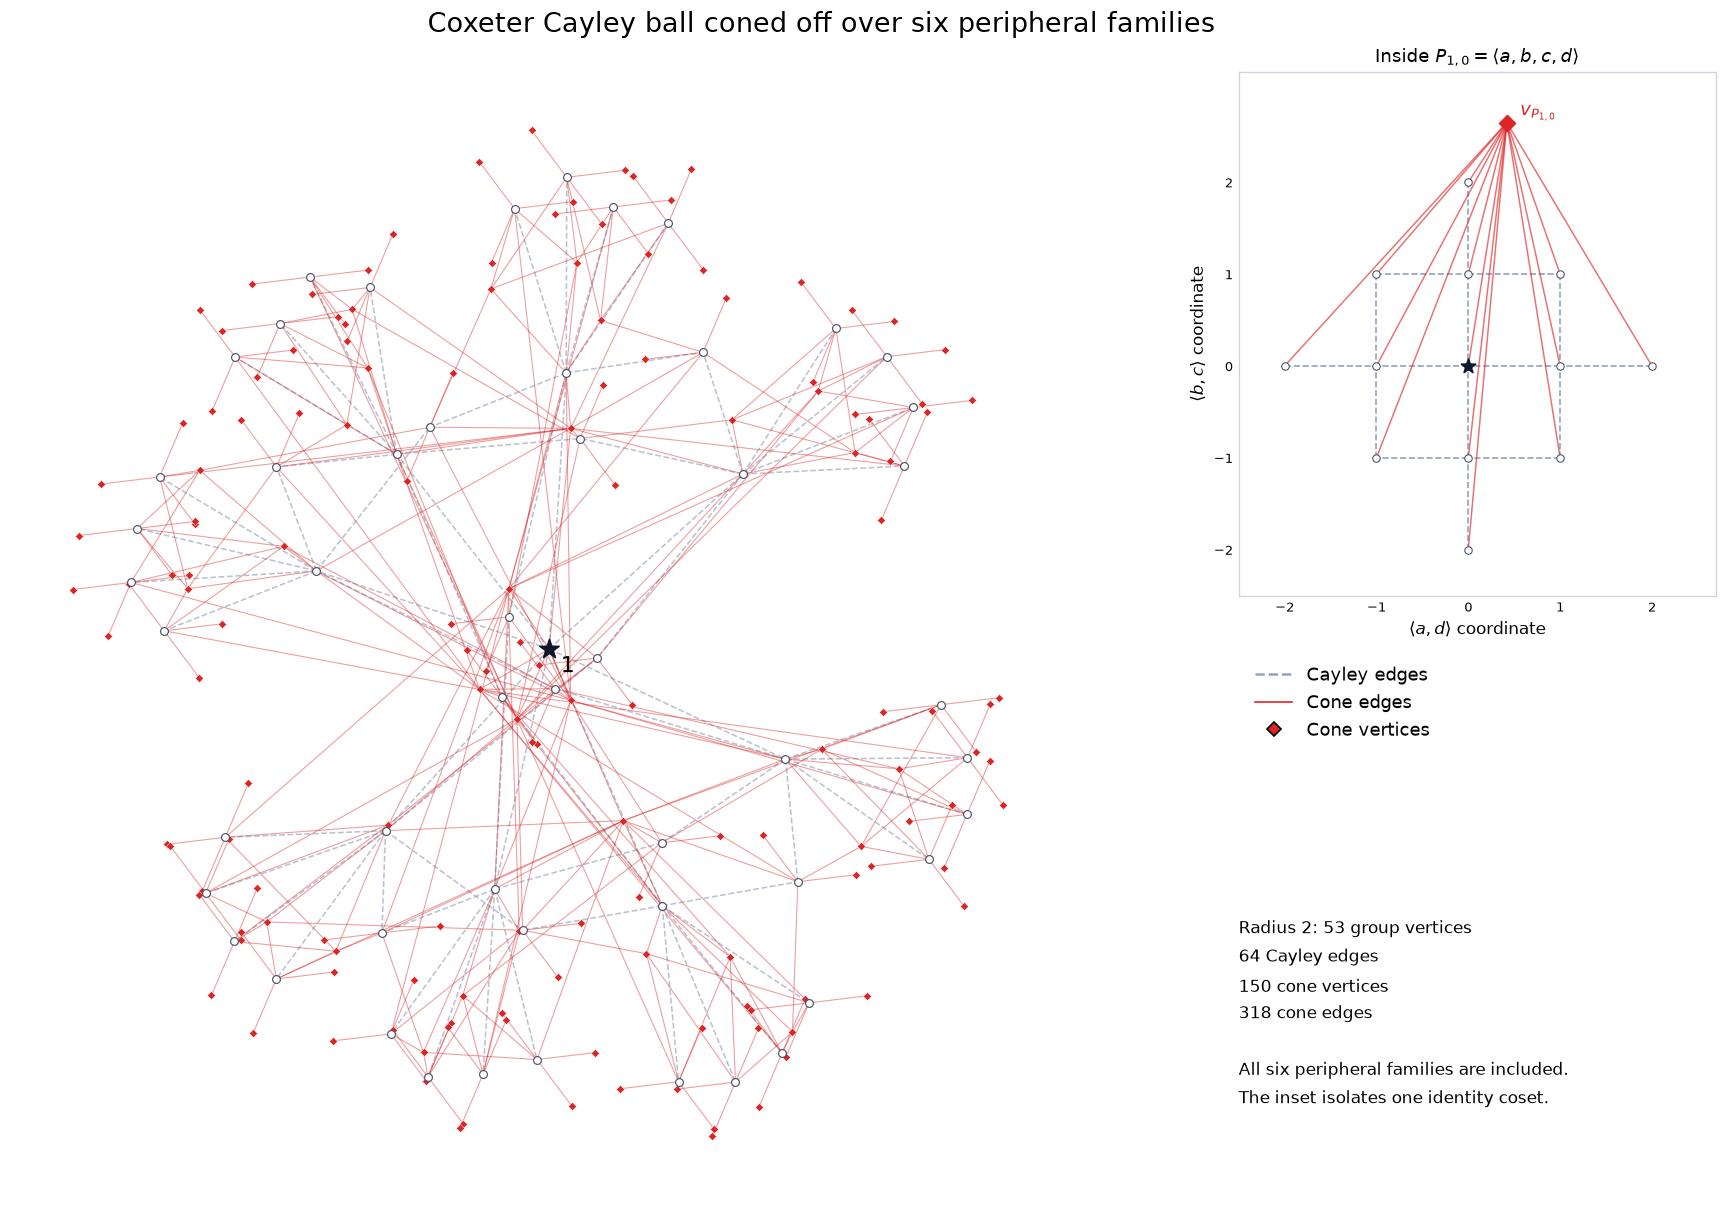

Added 150 cone vertices and 318 cone edges.


In [12]:
coned_ball = cayley_ball.copy()
nx.set_node_attributes(coned_ball,'group','kind')
nx.set_edge_attributes(coned_ball,'cayley','kind')
cone_vertices = {key: ('cone',key) for key in peripheral_cosets}
cone_positions = {}
for key,members in peripheral_cosets.items():
    family,representative = key
    family_number = 2*family[0]+family[1]
    angle = 2*np.pi*family_number/6 + 0.12
    offset = 0.32*plot_spacing*np.array([np.cos(angle),np.sin(angle)])
    center = np.mean([cayley_pos[g] for g in members],axis=0)
    cone_positions[key] = center+offset
    cone = cone_vertices[key]
    coned_ball.add_node(cone,kind='cone',family=family,representative=representative)
    coned_ball.add_edges_from((cone,g,{'kind':'cone'}) for g in members)
assert coned_ball.number_of_nodes() == len(cayley_ball)+len(peripheral_cosets)
assert coned_ball.number_of_edges() == cayley_ball.number_of_edges()+6*len(cayley_ball)
assert all(set(coned_ball.neighbors(cone_vertices[key])) == set(members)
           for key,members in peripheral_cosets.items())
assert all(sum(coned_ball.nodes[h]['kind']=='cone' for h in coned_ball[g])==6 for g in cayley_ball)

fig_coned = draw_coxeter_cayley('coned')
fig_coned.savefig('coxeter_coned_cayley_ball.png',dpi=300,bbox_inches='tight')
plt.show()
print(f'Added {len(peripheral_cosets)} cone vertices and {6*len(cayley_ball)} cone edges.')

## 8. The Cayley graph alone, and a highlighted word path

The first figure keeps the same group vertices, coordinates, and peripheral inset as Sections 6–7, with all Cayley edges dashed grey. The following cell highlights the path $1\to a\to ac$ with arrows along its edges. The word `ac` is a shortlex geodesic; since $a$ and $c$ commute, the path $1\to c\to ca=ac$ is another geodesic to the same endpoint, but it is not the chosen shortlex representative.

Change `highlight_word` to draw another word path. If it leaves the current ball, increase `cayley_radius` in Section 6 and rerun the plotting cells. All drawings reuse the same finite Cayley ball and do not change the automaton.

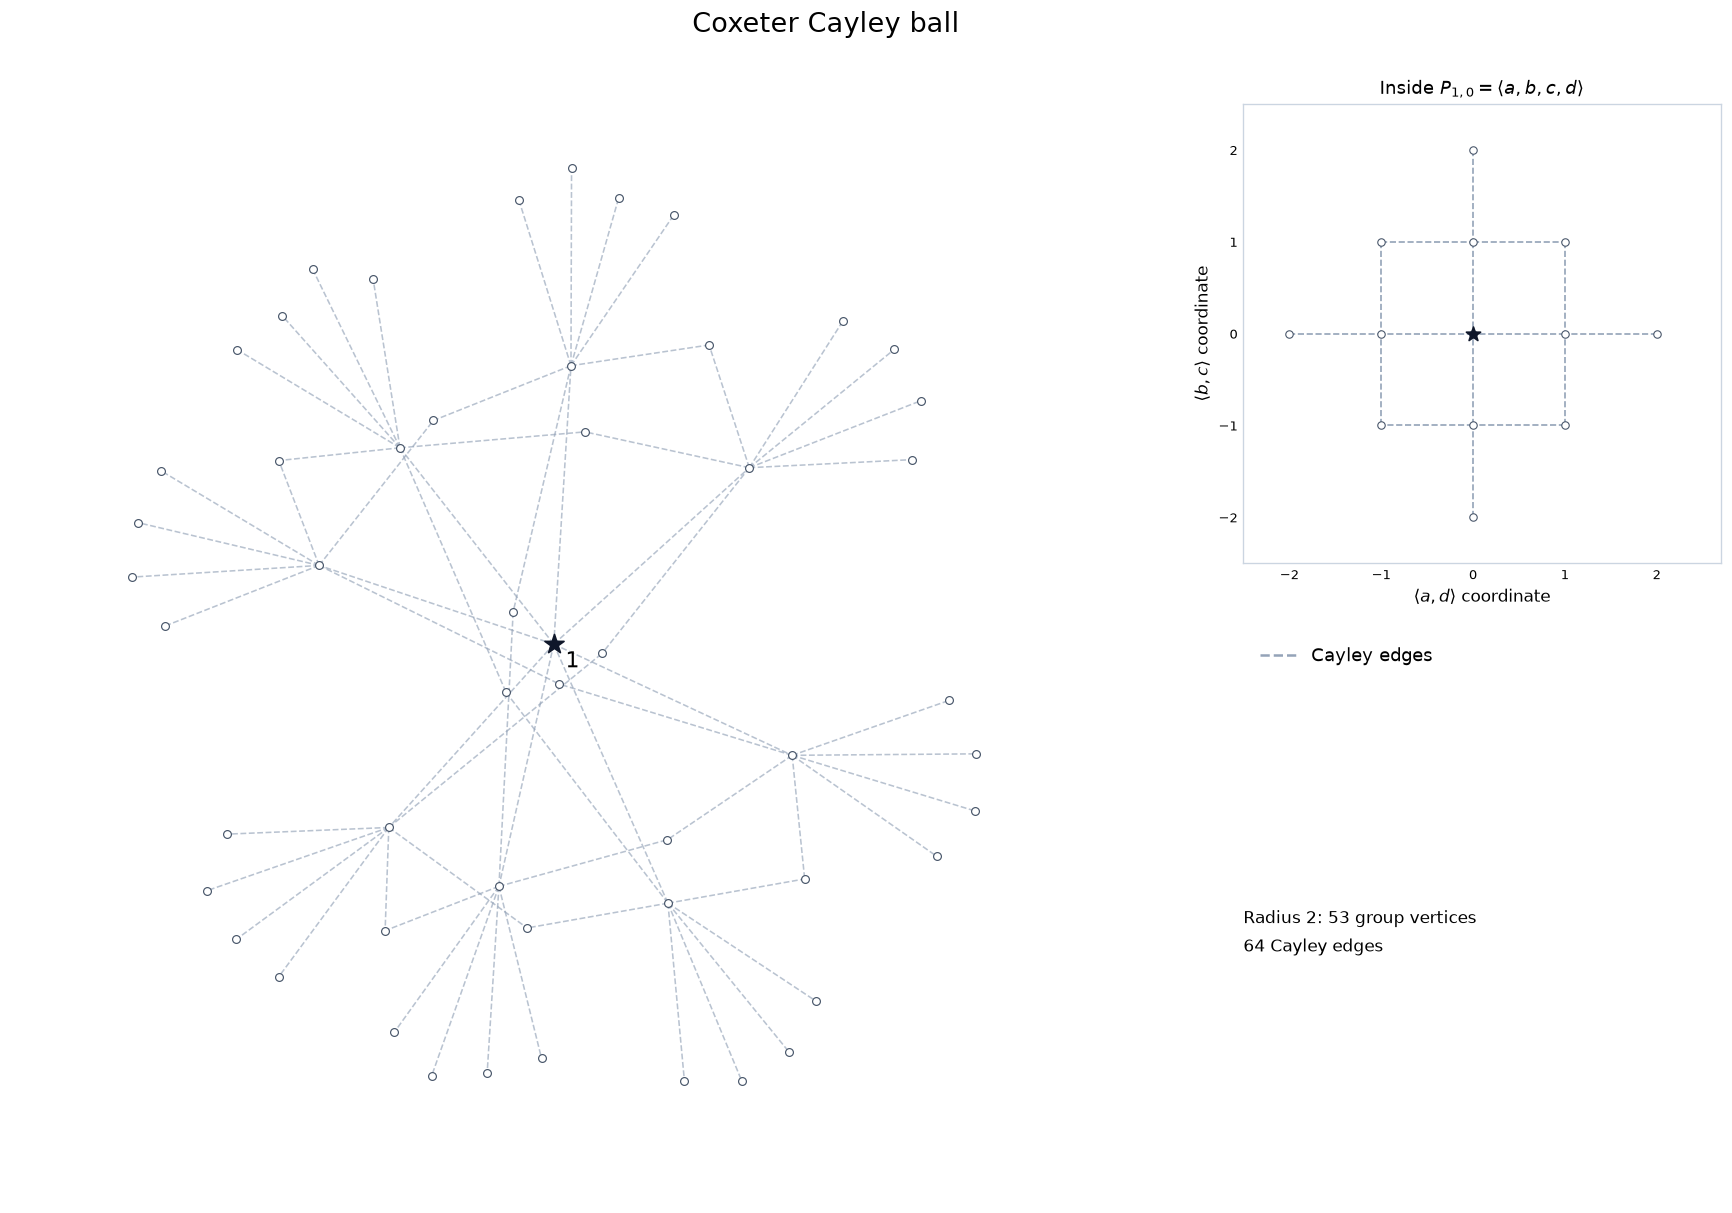

In [13]:
fig_cayley = draw_coxeter_cayley('plain')
fig_cayley.savefig('coxeter_cayley_ball.png',dpi=300,bbox_inches='tight')
plt.show()

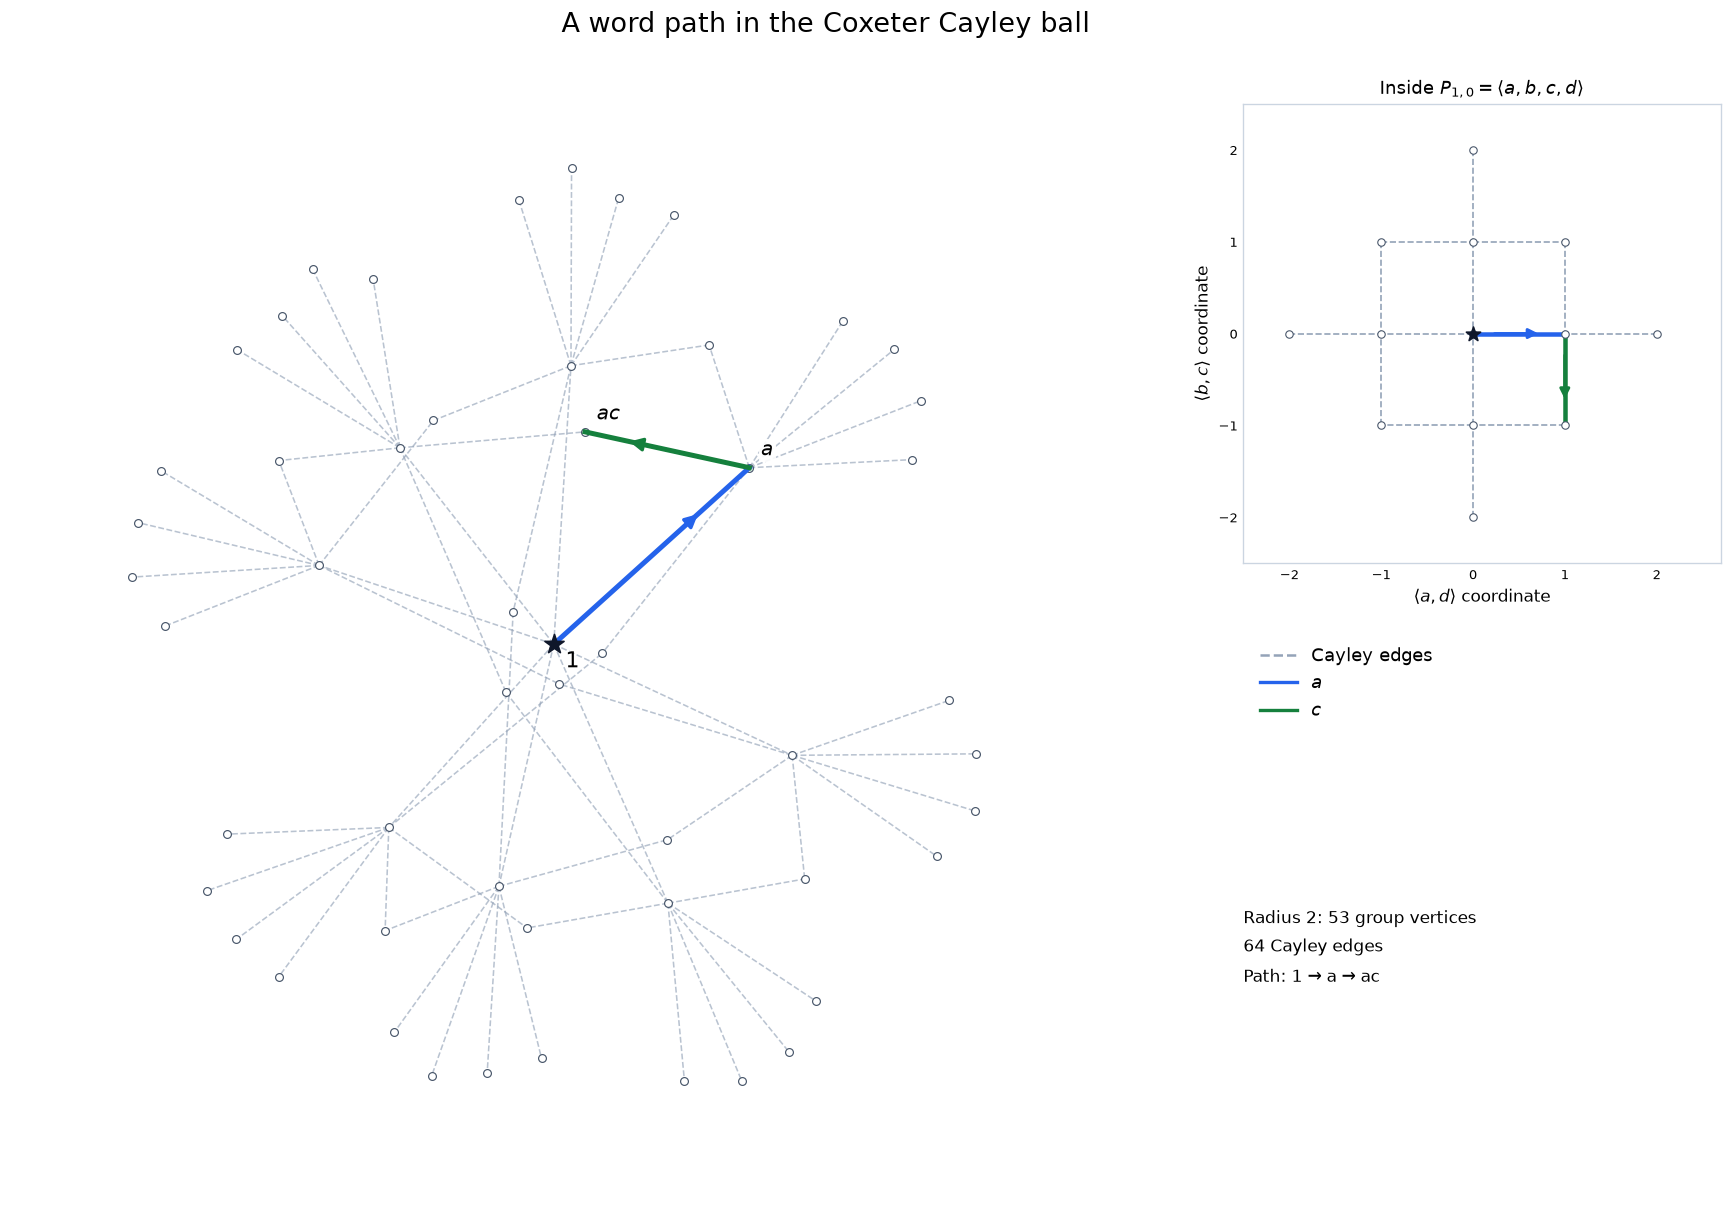

In [14]:
highlight_word = tuple('ac')
if any(s not in letters for s in highlight_word):
    raise ValueError(f'Use only the generators {letters}.')
fig_path = draw_coxeter_cayley('path',highlight_word=highlight_word)
fig_path.savefig('coxeter_cayley_word_path.png',dpi=300,bbox_inches='tight')
plt.show()

## 9. Ordered frequencies along random geodesic paths

We sample one path starting at $q_0$ using the Perron–Frobenius transition matrix $N$. For a target word $w$ of length $k$, its ordered frequency after $m$ complete blocks is
$$F_w(m)=\frac{1}{m}\sum_{j=0}^{m-1}\mathbf{1}\{\sigma_{jk}\cdots\sigma_{(j+1)k-1}=w\}.$$
Only aligned, disjoint blocks are counted; any incomplete trailing block is discarded. The exact stationary comparison is
$$p_\mu(w)=\sum_{x\in V(\mathcal G)}\mu_x\,\mathbb P_x(\text{next }k\text{ labels are }w).$$
The unique recurrent component is irreducible and aperiodic, so its $k$-step chain is ergodic for every $k\geq1$, and these empirical frequencies converge almost surely to $p_\mu(w)$. The group Cayley graph is bipartite, but this does **not** force the automaton's recurrent component to have period two.

All eight generators are involutions: there are no separate uppercase inverse letters. For example, `aa` is not geodesic, while `ba` is geodesic but is not our selected representative because $ab=ba$ and $a<b$. Both have stationary probability zero. The noncommuting letters `a` and `g` give valid alternating words such as `agagag`, a useful rare-word target.

Edit `path_length`, `seed`, and `target_words` below. The default is 100,000 letters; larger samples can be requested explicitly. The plots reuse this sample. The table includes exact symbolic probabilities as well as decimals. Empty targets and unknown letters are rejected; frequencies with no complete blocks are undefined.


Combing automaton for reference:

<img src="coxeter_automaton.png" width="850">


In [15]:
# Configuration: all targets are measured on the same seeded path.
path_length = 100_000
seed = 67
target_words = ['a', 'ab', 'ba', 'ag', 'agag', 'agagag']

from IPython.display import Markdown

frequency_next = {v: dict(outgoing) for v, outgoing in transitions.items()}
frequency_N = np.array(N, dtype=float)
assert np.all(frequency_N >= 0) and np.allclose(frequency_N.sum(axis=1), 1)


def random_geodesic_ray(n, seed=None, return_states=False):
    """Sample n edge labels from q0 using N; optionally return all n+1 states."""
    if not isinstance(n, (int, np.integer)) or n < 0:
        raise ValueError('n must be a nonnegative integer')
    rng = np.random.default_rng(seed)
    outgoing_probs = {v: np.array([frequency_N[idx[v], idx[t]] for _, t in transitions[v]])
                      for v in states}
    assert all(np.isclose(p.sum(), 1) for p in outgoing_probs.values())
    word, state_path, current = [], ['q0'], 'q0'
    for _ in range(n):
        choice = rng.choice(len(transitions[current]), p=outgoing_probs[current])
        letter, current = transitions[current][choice]
        word.append(letter)
        state_path.append(current)
    return (word, state_path) if return_states else word


def frequency_target(word):
    """Normalize a target over the generator alphabet; admissibility is separate."""
    word = tuple(word)
    if not word:
        raise ValueError('The target word must be nonempty')
    if any(s not in letters for s in word):
        raise ValueError(f'Unknown generator: use only {letters}')
    return word


def ordered_frequency(word_w, sigma):
    """Count aligned complete blocks; validate the sample against this automaton."""
    w, sample = frequency_target(word_w), tuple(sigma)
    current = 'q0'
    for i, s in enumerate(sample):
        if s not in frequency_next[current]:
            raise ValueError(f'Sample is not a combing path at position {i}: {current} --{s}--> ?')
        current = frequency_next[current][s]
    k = len(w)
    num_blocks = len(sample) // k
    count = sum(sample[j*k:(j+1)*k] == w for j in range(num_blocks))
    return {'count': count, 'num_blocks': num_blocks,
            'frequency': count / num_blocks if num_blocks else float('nan')}


def stationary_word_probability(word_w):
    """Exact stationary probability, summing all compatible starting vertices."""
    word = frequency_target(word_w)
    probability = sp.S.Zero
    for source in states:
        current, weight = source, mu[idx[source]]
        for s in word:
            target = frequency_next[current].get(s)
            if target is None:
                weight = sp.S.Zero
                break
            weight *= N[idx[current], idx[target]]
            current = target
        probability += weight
    return sp.simplify(probability)


sigma, sampled_state_path = random_geodesic_ray(path_length, seed=seed, return_states=True)
assert len(sampled_state_path) == len(sigma) + 1 and sampled_state_path[0] == 'q0'
assert all(frequency_next[u].get(s) == v
           for u, s, v in zip(sampled_state_path, sigma, sampled_state_path[1:]))

# Small checks distinguish disjoint blocks from overlapping windows.
assert ordered_frequency('ag', 'agaga') == {'count': 2, 'num_blocks': 2, 'frequency': 1.0}
assert ordered_frequency('ga', 'agag')['count'] == 0
assert stationary_word_probability('ba') == 0
assert stationary_word_probability('aa') == 0
assert sp.simplify(sum(stationary_word_probability(s) for s in letters)) == 1

frequency_results = []
for word in target_words:
    result = ordered_frequency(word, sigma)
    result.update(word=''.join(word), stationary_probability=stationary_word_probability(word))
    frequency_results.append(result)

print(f'N-weighted path from q0: {path_length:,} letters; seed={seed}.')
print('First 60 letters:', ''.join(sigma[:60]))
print('Exact stationary values are stored in frequency_results.')
rows = ['| Word | Count | Complete blocks | Empirical frequency | Stationary limit | Exact stationary limit |',
        '|:--|--:|--:|--:|--:|:--|']
for result in frequency_results:
    rows.append(f"| `{result['word']}` | {result['count']:,} | {result['num_blocks']:,} | "
                f"{result['frequency']:.6f} | {float(result['stationary_probability']):.6f} | "
                f"${sp.latex(result['stationary_probability'])}$ |")
display(Markdown('\n'.join(rows)))


N-weighted path from q0: 100,000 letters; seed=67.
First 60 letters: cbecfcdebhabghedecdefcdfafgabecgabecfgfadefhbebgabebdafhacdg
Exact stationary values are stored in frequency_results.


| Word | Count | Complete blocks | Empirical frequency | Stationary limit | Exact stationary limit |
|:--|--:|--:|--:|--:|:--|
| `a` | 12,484 | 100,000 | 0.124840 | 0.125000 | $\frac{1}{8}$ |
| `ab` | 726 | 50,000 | 0.014520 | 0.014583 | $\frac{7}{480}$ |
| `ba` | 0 | 50,000 | 0.000000 | 0.000000 | $0$ |
| `ag` | 1,061 | 50,000 | 0.021220 | 0.021667 | $\frac{13}{600}$ |
| `agag` | 14 | 25,000 | 0.000560 | 0.000867 | $\frac{13}{15000}$ |
| `agagag` | 1 | 16,666 | 0.000060 | 0.000035 | $\frac{13}{375000}$ |

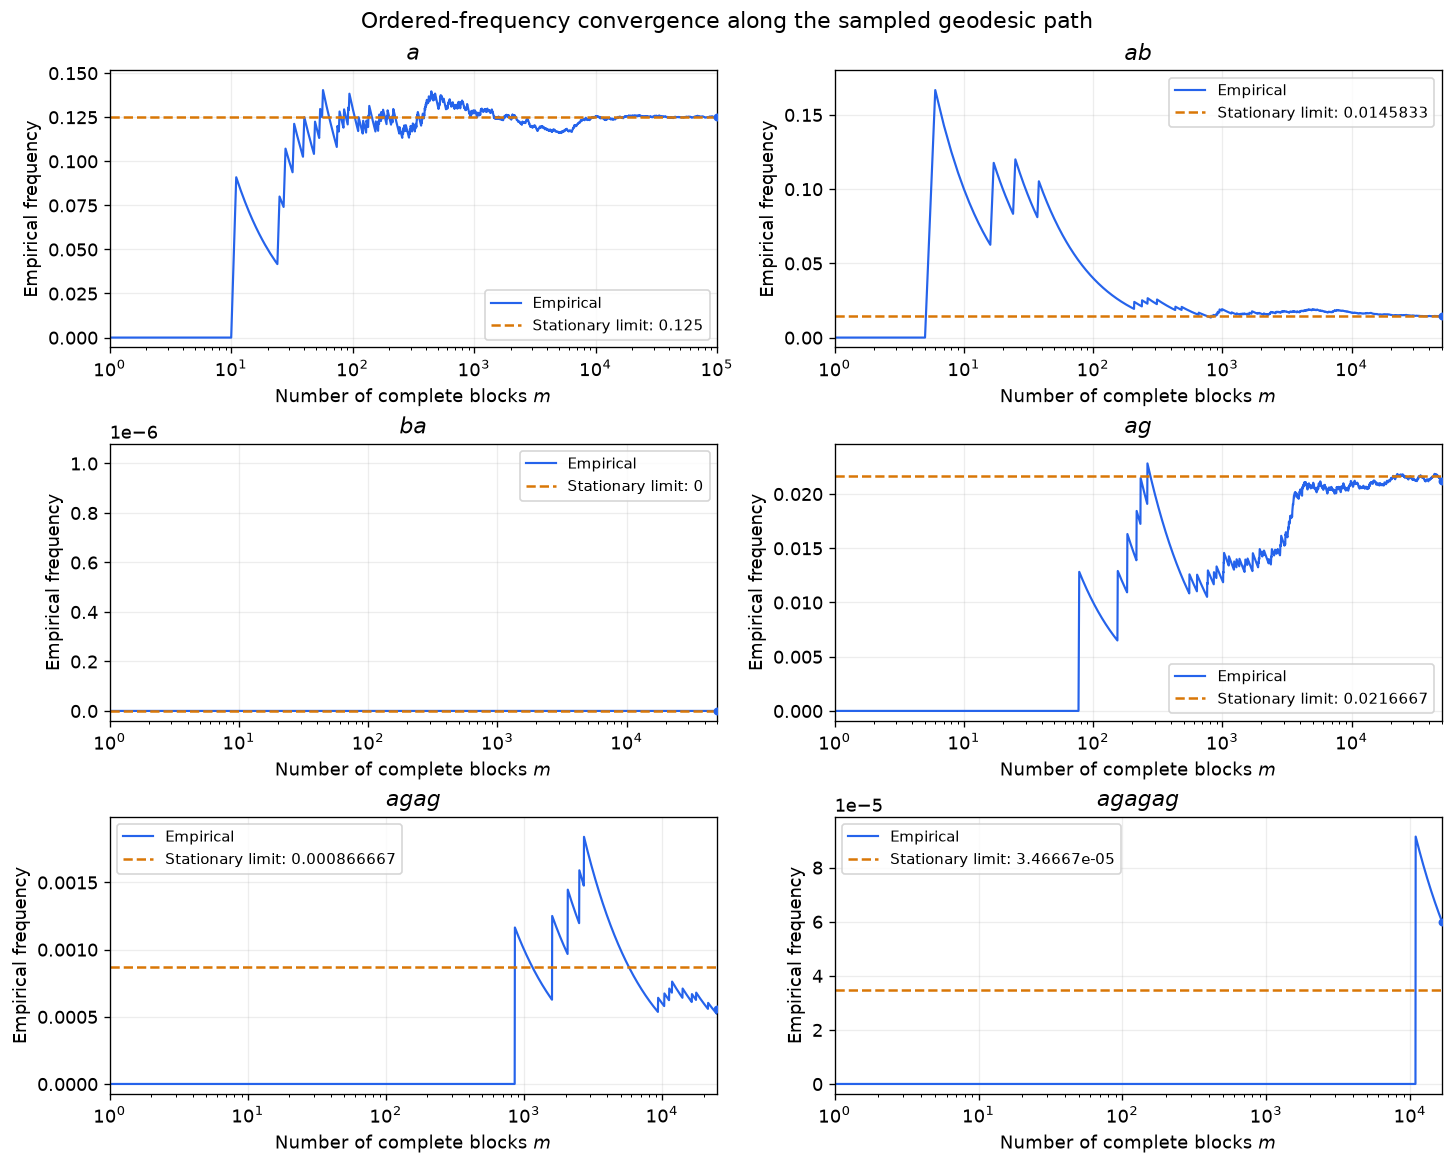

In [16]:
# Cumulative ordered frequencies on the SAME sampled path sigma from above.
# The horizontal axis counts complete, disjoint blocks of the target's length.
import numpy as np
import matplotlib.pyplot as plt

convergence_xscale = 'log'  # Change to 'linear' for equally spaced block counts.
convergence_max_points = 3000  # Plot fewer points on long paths; count every block.

if not target_words:
    raise ValueError('Set at least one target word in the preceding cell.')
if convergence_xscale not in {'log', 'linear'}:
    raise ValueError("convergence_xscale must be 'log' or 'linear'.")
if convergence_max_points < 2:
    raise ValueError('convergence_max_points must be at least 2.')

convergence_sample = np.asarray(sigma, dtype='U1')
convergence_columns = min(2, len(target_words))
convergence_rows = (len(target_words) + convergence_columns - 1) // convergence_columns
fig_frequency, frequency_axes = plt.subplots(
    convergence_rows, convergence_columns,
    figsize=(12, 3.2 * convergence_rows), squeeze=False, constrained_layout=True)
frequency_convergence = {}

for axis, target in zip(frequency_axes.flat, target_words):
    word = frequency_target(target)
    k = len(word)
    num_blocks = len(convergence_sample) // k
    limit = float(stationary_word_probability(word))
    axis.set_title('$' + ''.join(letter_tex[s].strip() for s in word) + '$')
    axis.set_xlabel('Number of complete blocks $m$')
    axis.set_ylabel('Empirical frequency')
    axis.set_xscale(convergence_xscale)
    axis.grid(True, alpha=0.22)

    if num_blocks:
        blocks = convergence_sample[:num_blocks*k].reshape(num_blocks, k)
        hits = np.all(blocks == np.asarray(word, dtype='U1'), axis=1)
        block_counts = np.arange(1, num_blocks + 1)
        cumulative_frequencies = np.cumsum(hits, dtype=np.int64) / block_counts
        # All frequencies are computed; only the drawing is downsampled.
        number_to_plot = min(num_blocks, convergence_max_points)
        spacing = np.geomspace if convergence_xscale == 'log' else np.linspace
        plot_indices = np.unique(spacing(1, num_blocks, number_to_plot).astype(int)) - 1
        axis.plot(block_counts[plot_indices], cumulative_frequencies[plot_indices],
                  color='#2563eb', lw=1.3, label='Empirical')
        axis.scatter([num_blocks], [cumulative_frequencies[-1]],
                     color='#2563eb', s=14, zorder=4)
        axis.axhline(limit, color='#d97706', ls='--', lw=1.5,
                     label=f'Stationary limit: {limit:.6g}')
        # Keep rare-word limits visible even when no occurrences were sampled.
        frequency_scale = max(float(cumulative_frequencies.max()), limit, 1e-6)
        axis.set_ylim(-0.04 * frequency_scale, 1.08 * frequency_scale)
        if num_blocks > 1:
            axis.set_xlim(1, num_blocks)
        frequency_convergence[''.join(word)] = {
            'blocks': block_counts, 'frequencies': cumulative_frequencies,
            'stationary_probability': limit}
        axis.legend(fontsize=9, loc='best')
    else:
        axis.text(0.5, 0.5, 'No complete blocks in this sample',
                  transform=axis.transAxes, ha='center', va='center')
        frequency_convergence[''.join(word)] = {
            'blocks': np.array([], dtype=int), 'frequencies': np.array([]),
            'stationary_probability': limit}

for axis in list(frequency_axes.flat)[len(target_words):]:
    axis.set_visible(False)
fig_frequency.suptitle('Ordered-frequency convergence along the sampled geodesic path')
fig_frequency.savefig('coxeter_ordered_frequency_convergence.png', dpi=300, bbox_inches='tight')
plt.show()


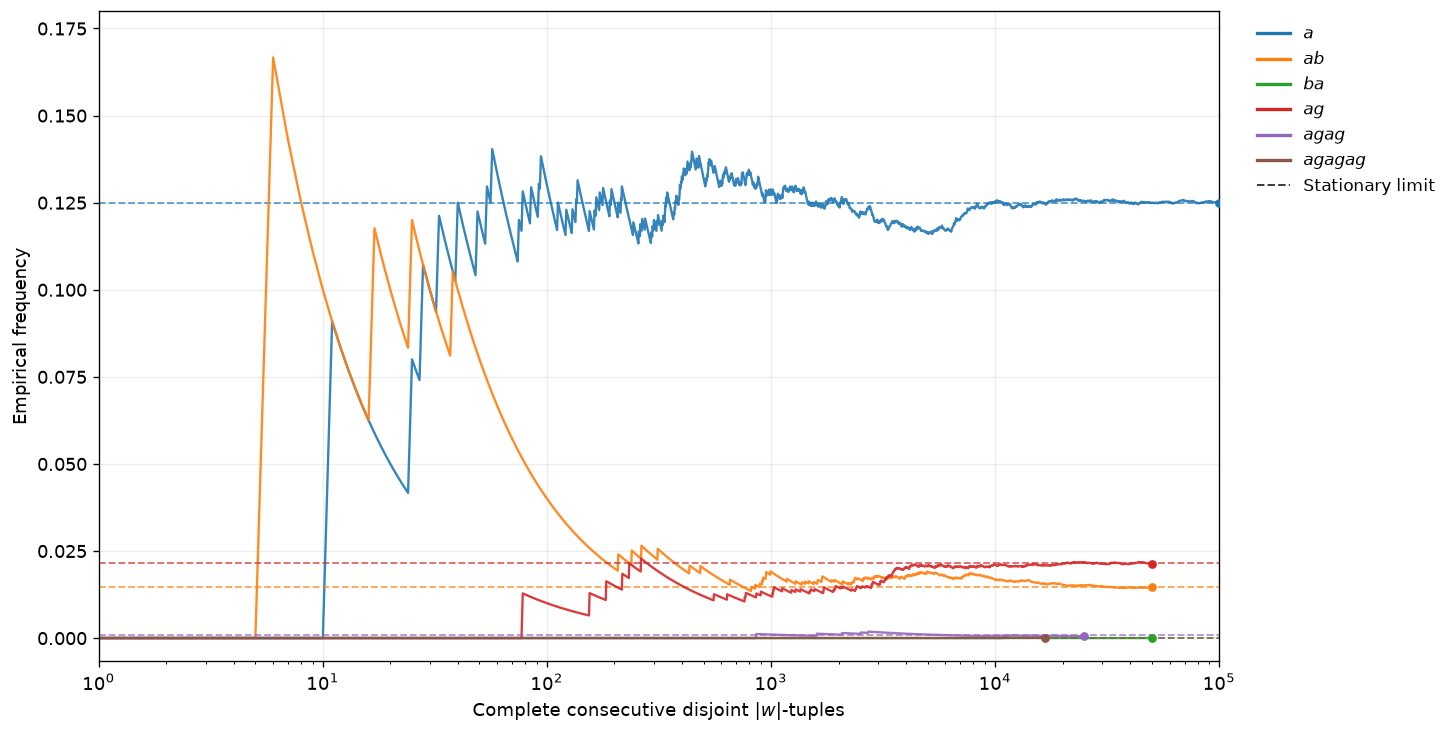

In [17]:
# Overlay the curves computed in the preceding cell; do not sample a new path.
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

fig_frequency_all, ax_frequency_all = plt.subplots(figsize=(12, 6), constrained_layout=True)
combined_colors = plt.get_cmap('tab10' if len(frequency_convergence) <= 10 else 'tab20')
combined_handles = []
combined_max_blocks = 0
combined_max_frequency = 0.0

for j, (word, curve) in enumerate(frequency_convergence.items()):
    counts = curve['blocks']
    empirical = curve['frequencies']
    limit = curve['stationary_probability']
    color = combined_colors(j % combined_colors.N)
    label = '$' + ''.join(letter_tex[s].strip() for s in word) + '$'
    combined_handles.append(Line2D([0], [0], color=color, lw=2, label=label))
    if len(counts):
        number_to_plot = min(len(counts), convergence_max_points)
        spacing = np.geomspace if convergence_xscale == 'log' else np.linspace
        selected = np.unique(spacing(1, len(counts), number_to_plot).astype(int)) - 1
        ax_frequency_all.plot(counts[selected], empirical[selected],
                               color=color, lw=1.4, alpha=0.9)
        ax_frequency_all.scatter(counts[-1], empirical[-1], color=color, s=18, zorder=4)
        combined_max_blocks = max(combined_max_blocks, int(counts[-1]))
        combined_max_frequency = max(combined_max_frequency, float(empirical.max()))
    ax_frequency_all.axhline(limit, color=color, ls='--', lw=1.1, alpha=0.7)
    combined_max_frequency = max(combined_max_frequency, limit)

combined_handles.extend([
    # Line2D([0], [0], color='#334155', lw=1.5, label='Empirical frequency'),
    Line2D([0], [0], color='#334155', lw=1.2, ls='--', label='Stationary limit')])
ax_frequency_all.legend(handles=combined_handles, loc='upper left',
                         bbox_to_anchor=(1.02, 1), frameon=False, fontsize=10)
ax_frequency_all.set_xscale(convergence_xscale)
if combined_max_blocks > 1:
    ax_frequency_all.set_xlim(1, combined_max_blocks)
ax_frequency_all.set_yscale('linear')
combined_scale = max(combined_max_frequency, 1e-6)
ax_frequency_all.set_ylim(-0.04 * combined_scale, 1.08 * combined_scale)
ax_frequency_all.set_xlabel('Complete consecutive disjoint $|w|$-tuples')
ax_frequency_all.set_ylabel('Empirical frequency')
# ax_frequency_all.set_title('Ordered-frequency convergence: all target words')
ax_frequency_all.grid(True, alpha=0.22)
fig_frequency_all.savefig('coxeter_ordered_frequency_convergence_combined.png',
                           dpi=300, bbox_inches='tight')
plt.show()


## References and conventions

- Jankiewicz–Norin–Wise, *Virtually fibering right-angled Coxeter groups*, §§5.a.1 and 5.i: the cube defining graph and its ideal-octahedron reflection group. [Author manuscript](https://www.math.mcgill.ca/wise/papers/RaCgFiBeReD).
- Caprace, *Buildings with isolated subspaces and relatively hyperbolic Coxeter groups* (2009): relative hyperbolicity and virtually abelian peripheral subgroups. [Paper](https://msp.org/iig/2009/10-1/iig-v10-n1-p02-s.pdf). In this example the peripherals are the six cusp groups of the ideal octahedron.
- Jillson–Levitin–Saldin–Stuopis–Wang–Xue, *Finite-State Machines for Horospheres in Hyperbolic Right-Angled Coxeter Groups*, Proposition 3.2 and Remark 3.3: the forbidden-set shortlex automaton, whose construction applies to an arbitrary defining graph. [arXiv:2406.18774](https://arxiv.org/abs/2406.18774).
- Munro–Osajda–Przytycki, *2-dimensional Coxeter groups are biautomatic*, Theorem 1.1: a geodesic biautomatic language over the Coxeter generating set. [arXiv:2006.07947](https://arxiv.org/abs/2006.07947). The cube is triangle-free, so its Coxeter system is 2-dimensional; this supplies admissibility of the eight-generator set in the manuscript's sense. We do not need to identify that biautomatic language with the shortlex language used here.
- The normalization of $r,l,N,\mu$ follows [the geodesic-combing section of the manuscript](../ordered_frequency_git/sections/geodesic_combings.tex), and disjoint-block frequencies follow [the ordered-frequency section](../ordered_frequency_git/sections/ordered_frequency.tex).

The cube is the **commutation graph**: its edges encode $m_{st}=2$, and nonedges encode $m_{st}=\infty$. This is not the usual Coxeter-diagram convention. All eight letters are their own inverses. The peripheral groups are $D_\infty\times D_\infty$, not $\mathbb Z^2$ themselves; each contains a translation subgroup $\mathbb Z^2$ of index four.

Every figure cell saves a PNG beside this notebook. Run the notebook from top to bottom. The finite balls are illustrative truncations; their finite coned graphs do not replace the infinite relative Cayley graph in the definition of relative hyperbolicity.
